# Chapter 8 — Support Vector Machines

*Chapter 7 ended with a curious fact: gradient descent on the logistic loss, run on separable data, drifts toward the separating hyperplane with the largest margin, and that hyperplane depends only on the few training examples that sit on the margin. This chapter starts from that hyperplane. We derive the support vector machine from the geometry of the margin, obtain its dual problem and see why the solution is sparse in the examples, extend it to data that cannot be separated with the hinge loss, solve it with a subgradient method and with the SMO algorithm, and measure what the margin buys in generalization.*

## 8.1 Learning objectives

Chapters 3 and 6 gave two separate reasons to look for a large margin. Theorem 3.7 bounds the error of a linear classifier by the fraction of training points below a margin $\gamma$ plus a term proportional to $\lVert\mathbf{w}\rVert/\gamma$, so that a classifier with a *large margin and a small norm* generalizes well whatever the dimension. Section 6.4.4 found that on separable data the logistic regression has no maximum-likelihood estimate and that the weights diverge, and Section 7.7.3 showed where the direction of the divergence leads. The support vector machine (SVM) turns this around: instead of waiting for an optimizer to find a large margin, it asks for the largest margin directly, as the solution of a convex optimization problem.

After working through the chapter you will be able to:

1. define the **geometric margin** of a hyperplane and formulate the **hard-margin SVM** as the quadratic program "minimize $\tfrac12\lVert\mathbf{w}\rVert^2$ subject to $y_i(\mathbf{w}^\top\mathbf{x}_i + b)\ge 1$";
2. derive the **dual problem** and the **KKT conditions**, and use them to show that $\mathbf{w}$ is a combination of the **support vectors** only, that the margin is $2/\lVert\mathbf{w}\rVert$ and that $\lVert\mathbf{w}\rVert^2 = \sum_i\alpha_i$;
3. solve a small SVM by hand, through the guess of the support set and the verification of the KKT conditions;
4. extend the formulation to non-separable data with **slack variables**, show that it is the minimization of the **hinge loss** plus a ridge penalty with $\lambda = 1/(Cn)$, and interpret the three kinds of examples ($\alpha_i = 0$, $0 < \alpha_i < C$, $\alpha_i = C$);
5. explain what the hinge loss estimates (the **Bayes classifier itself**, not the probabilities) and compare it with the logistic loss;
6. prove the convergence rate of the **subgradient method** with the step $1/(\lambda k)$, derive the **SMO** update, and implement both from scratch;
7. state and prove the **leave-one-out bound** $\widehat{\mathrm{err}}_{\mathrm{LOO}}\le\#\mathrm{SV}/n$, evaluate the margin bound of Chapter 3 on a real data set and choose $C$ with the protocols of Chapter 5;
8. use SVMs in practice with scikit-learn (feature scaling, comparison with logistic regression, probabilities by Platt scaling, multiclass by one-vs-one and one-vs-rest), and see how the dual form leads to **kernels** (Chapter 9) and to **support vector regression**.

**Prerequisites.** Chapters 1 to 7. In particular the margin bound of Section 3.8.4, the cross-validation protocols and McNemar's test of Chapter 5, regularized logistic regression and the meaning of $C$ (Section 6.5), the dual form of ridge regression (Proposition 6.12), and the implicit bias of gradient descent (Section 7.7.3). Constrained optimization is used through Lagrange multipliers; every step is derived here.

:::{admonition} A word about the data in this chapter
:class: note
The experiments use real data sets, all shipped with scikit-learn: **Iris** (two petal measurements, for pictures in the plane), **Breast Cancer** (the main example: the stratified split of Chapters 6 and 7, with 426 training and 143 test patients, malignant $= 1$), **Digits** (multiclass) and **Diabetes** (regression). The only constructions that are not data are the five points of Worked example 8.1, small enough to be solved by hand, and the explicit-feature check of Section 8.8, which is a numerical identity. In this chapter the two classes are labeled $y_i \in \{-1, +1\}$, as in Section 3.8.4, and the **score** of an example is $f(\mathbf{x}) = \mathbf{w}^\top\mathbf{x} + b$ with the intercept $b$ kept apart from $\mathbf{w}$ (unlike Chapter 7, where it was one of the coordinates).
:::

### Setting up this notebook

As in the previous chapters, the next two cells print the versions of the libraries and define the plotting style and the random seed.

In [1]:
import platform
from importlib.metadata import version

print("Python", platform.python_version())
for pkg in ["numpy", "scipy", "pandas", "matplotlib", "scikit-learn"]:
    print(f"{pkg:<14}{version(pkg)}")

Python 3.15.2
numpy         2.5.5
scipy         1.18.1
pandas        3.1.1
matplotlib    3.11.2
scikit-learn  1.9.1


In [2]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import binomtest
from sklearn.calibration import CalibratedClassifierCV
from sklearn.datasets import load_breast_cancer, load_diabetes, load_digits, load_iris
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, LogisticRegression, Perceptron, Ridge, SGDClassifier
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GridSearchCV, KFold, LeaveOneOut, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR, LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42  # fixed seed: random operations give the same result every time

# Plotting style used throughout the book (Okabe-Ito colors, safe for color-vision deficiencies).
BLUE, ORANGE, GREEN = "#0072B2", "#E69F00", "#009E73"
VERMILION, SKY, PURPLE = "#D55E00", "#56B4E9", "#CC79A7"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.4, 4.0),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

## 8.2 The hard-margin support vector machine

### 8.2.1 Margins and the largest-margin hyperplane

A linear classifier predicts $\operatorname{sign}(\mathbf{w}^\top\mathbf{x} + b)$. The hyperplane $H = \{\mathbf{x} : \mathbf{w}^\top\mathbf{x} + b = 0\}$ separates the space in two half-spaces, and the *size* of the score of a point says how far from $H$ it is.

:::{admonition} Proposition 8.1 (distance to a hyperplane)
The distance from a point $\mathbf{x}$ to the hyperplane $H$ is $\lvert\mathbf{w}^\top\mathbf{x} + b\rvert/\lVert\mathbf{w}\rVert$. Consequently, if $y_i(\mathbf{w}^\top\mathbf{x}_i + b)\ge 1$ for all $i$ and equality holds for at least one example of each class, the two parallel hyperplanes $\mathbf{w}^\top\mathbf{x} + b = \pm 1$ are at distance $2/\lVert\mathbf{w}\rVert$ from each other, and no training point lies between them.
:::

:::{admonition} Proof
:class: dropdown
Let $\mathbf{x}_0 \in H$ be the point of $H$ closest to $\mathbf{x}$. The vector $\mathbf{x} - \mathbf{x}_0$ is orthogonal to $H$, hence parallel to $\mathbf{w}$: $\mathbf{x} = \mathbf{x}_0 + t\,\mathbf{w}/\lVert\mathbf{w}\rVert$ for a real $t$, whose absolute value is the distance. Then $\mathbf{w}^\top\mathbf{x} + b = \mathbf{w}^\top\mathbf{x}_0 + b + t\lVert\mathbf{w}\rVert = t\lVert\mathbf{w}\rVert$, so $\lvert t\rvert = \lvert\mathbf{w}^\top\mathbf{x} + b\rvert/\lVert\mathbf{w}\rVert$. A point on $\mathbf{w}^\top\mathbf{x} + b = 1$ is at distance $1/\lVert\mathbf{w}\rVert$ from $H$, and one on $\mathbf{w}^\top\mathbf{x} + b = -1$ at the same distance on the other side. $\square$
:::

Suppose the training set is **linearly separable**: some $(\mathbf{w}, b)$ has $y_i(\mathbf{w}^\top\mathbf{x}_i + b) > 0$ for all $i$. There are then infinitely many separating hyperplanes (Figure 8.1), all with zero training error, and the question is which one to choose. The **geometric margin** of $(\mathbf{w}, b)$ is the distance from $H$ to the closest training point, $\gamma = \min_i y_i(\mathbf{w}^\top\mathbf{x}_i + b)/\lVert\mathbf{w}\rVert$. The score does not change in sign if we multiply $(\mathbf{w}, b)$ by a positive constant, and the margin is *invariant* under that change, so we may fix the scale by requiring that the closest points have score exactly $\pm 1$. In this scale $\gamma = 1/\lVert\mathbf{w}\rVert$ (Proposition 8.1) and maximizing the margin is the same as minimizing $\lVert\mathbf{w}\rVert$:

$$
\boxed{\ \min_{\mathbf{w}, b}\ \tfrac12\lVert\mathbf{w}\rVert^2 \quad\text{subject to}\quad y_i(\mathbf{w}^\top\mathbf{x}_i + b)\ \ge\ 1,\quad i = 1, \dots, n.\ }
\tag{hard-margin primal}
$$

This is a convex quadratic program: a strictly convex objective in $\mathbf{w}$ with $n$ linear inequality constraints. It has a solution if and only if the data are separable, and then the solution $\hat{\mathbf{w}}$ is unique (the objective is strictly convex in $\mathbf{w}$ and the feasible set is convex). The reason for choosing *this* hyperplane is the margin bound of Theorem 3.7: with the constraints $y_i f(\mathbf{x}_i)\ge 1$ the first term of the bound (the fraction of points with margin below $\gamma = 1$) is zero, and the second term is proportional to $\lVert\mathbf{w}\rVert$, which is the quantity that the SVM minimizes. Among all the separating hyperplanes, it is the one with the smallest value of the bound.

The next two cells set up the data of this section. The first is **Worked example 8.1**, five points in the plane small enough to solve by hand. The second is the data of Figure 8.1(b): the petal length and width of the setosa and versicolor flowers of Iris (100 flowers, 50 in each class), a real separable problem in two dimensions.

### Worked example 8.1 — a five-point SVM by hand

Take the negative points $\mathbf{x}_1 = (0, 0)$, $\mathbf{x}_2 = (2, 0)$ and the positive points $\mathbf{x}_3 = (1, 2)$, $\mathbf{x}_4 = (3, 3)$, $\mathbf{x}_5 = (0, 4)$. *This data set is constructed, to be solved in closed form.* Looking at the picture (Figure 8.1(a)), the closest points of the two classes are $\mathbf{x}_3$ and the segment between $\mathbf{x}_1$ and $\mathbf{x}_2$: guess that the support vectors are $\mathbf{x}_1, \mathbf{x}_2, \mathbf{x}_3$, that is, that the constraints of these three points hold with equality and the others are slack. The equalities are

$$
\begin{aligned}
\mathbf{x}_1:&\quad -(b) = 1 &&\Rightarrow\ b = -1,\\
\mathbf{x}_2:&\quad -(2w_1 + b) = 1 &&\Rightarrow\ 2w_1 = -b - 1 = 0,\ \ w_1 = 0,\\
\mathbf{x}_3:&\quad w_1 + 2w_2 + b = 1 &&\Rightarrow\ 2w_2 = 2,\ \ w_2 = 1.
\end{aligned}
$$

So $\mathbf{w} = (0, 1)$, $b = -1$, and the margin is $1/\lVert\mathbf{w}\rVert = 1$ (the two margin hyperplanes, $w_2 = 0$ and $w_2 = 2$, are at distance 2). The guess is right if the other constraints hold: $\mathbf{x}_4$ has score $3 - 1 = 2 \ge 1$ and $\mathbf{x}_5$ has $4 - 1 = 3 \ge 1$. That the guess is the *optimal* solution is what the dual of the next section proves: there we shall find $\boldsymbol\alpha = (\tfrac14, \tfrac14, \tfrac12, 0, 0)$. The code below solves the problem numerically (scikit-learn's `SVC` with a very large $C$ is a hard-margin SVM when the data are separable) and also with a general-purpose optimizer applied directly to the primal.

In [3]:
X_we = np.array([[0, 0], [2, 0], [1, 2], [3, 3], [0, 4]], dtype=float)           # constructed example
y_we = np.array([-1, -1, 1, 1, 1], dtype=float)

hard_we = SVC(kernel="linear", C=1e6, tol=1e-10).fit(X_we, y_we)
print("sklearn:      w =", hard_we.coef_.round(6).ravel(), " b =", hard_we.intercept_.round(6), " support vectors:", hard_we.support_ + 1)
print("alpha_i y_i for the support vectors:", hard_we.dual_coef_.round(6).ravel())

constraints = [{"type": "ineq", "fun": lambda v, i=i: y_we[i] * (X_we[i] @ v[:2] + v[2]) - 1} for i in range(len(y_we))]
primal = minimize(lambda v: 0.5 * v[:2] @ v[:2], x0=np.array([0.1, 0.1, 0.1]), constraints=constraints, method="SLSQP",
                  options={"ftol": 1e-14, "maxiter": 500})
print("direct primal: w =", primal.x[:2].round(6), " b =", primal.x[2].round(6))
print("scores of the five points:", (X_we @ hard_we.coef_.ravel() + hard_we.intercept_).round(4))

sklearn:      w = [0. 1.]  b = [-1.]  support vectors: [1 2 3]
alpha_i y_i for the support vectors: [-0.25 -0.25  0.5 ]
direct primal: w = [0. 1.]  b = -1.0
scores of the five points: [-1. -1.  1.  2.  3.]


### 8.2.2 The dual problem and the support vectors

The primal has $d + 1$ unknowns and $n$ constraints. Attaching a multiplier $\alpha_i \ge 0$ to each constraint gives the Lagrangian

$$
\mathcal{L}(\mathbf{w}, b, \boldsymbol\alpha) = \tfrac12\lVert\mathbf{w}\rVert^2 - \sum_{i=1}^n \alpha_i\big[y_i(\mathbf{w}^\top\mathbf{x}_i + b) - 1\big],
$$

and the derivation below shows how it leads to a different problem, in the $n$ unknowns $\alpha_i$, whose solution gives the one of the primal.

:::{admonition} Theorem 8.2 (dual problem and KKT conditions of the hard-margin SVM)
:class: tip
Let the data be separable. The primal has a unique solution $\hat{\mathbf{w}}$, and there are multipliers $\hat\alpha_i \ge 0$ that solve the **dual problem**

$$
\max_{\boldsymbol\alpha}\ \ \sum_{i=1}^n\alpha_i - \frac12\sum_{i=1}^n\sum_{j=1}^n\alpha_i\alpha_j\,y_iy_j\,\mathbf{x}_i^\top\mathbf{x}_j
\qquad\text{subject to}\qquad \alpha_i\ge 0,\quad \sum_{i=1}^n\alpha_iy_i = 0,
$$

with no gap between the primal and the dual optimal values. The solutions are linked by

$$
\hat{\mathbf{w}} = \sum_{i=1}^n\hat\alpha_i\,y_i\,\mathbf{x}_i,
\qquad
\hat\alpha_i\,\big[y_i(\hat{\mathbf{w}}^\top\mathbf{x}_i + \hat b) - 1\big] = 0\ \text{ for every } i\quad\text{(complementary slackness)}.
$$

Consequently: **(i)** only the examples on the margin ($y_i(\hat{\mathbf{w}}^\top\mathbf{x}_i + \hat b) = 1$), the **support vectors**, can have $\hat\alpha_i > 0$, and $\hat{\mathbf{w}}$ is a combination of them alone; **(ii)** $\lVert\hat{\mathbf{w}}\rVert^2 = \sum_i\hat\alpha_i$, so the margin is $1/\sqrt{\sum_i\hat\alpha_i}$; **(iii)** the data enter the dual only through the inner products $\mathbf{x}_i^\top\mathbf{x}_j$; **(iv)** the prediction is $\operatorname{sign}\big(\sum_i\hat\alpha_iy_i\,\mathbf{x}_i^\top\mathbf{x} + \hat b\big)$, and the intercept is obtained from any support vector, $\hat b = y_k - \hat{\mathbf{w}}^\top\mathbf{x}_k$.
:::

:::{admonition} Proof
:class: dropdown
*The dual function.* For fixed $\boldsymbol\alpha \ge 0$, minimize $\mathcal{L}$ over $(\mathbf{w}, b)$. The Lagrangian is convex and differentiable in $(\mathbf{w}, b)$, and it is bounded below only if the derivative in $b$ vanishes. Setting $\partial\mathcal{L}/\partial\mathbf{w} = \mathbf{w} - \sum_i\alpha_iy_i\mathbf{x}_i = \mathbf{0}$ and $\partial\mathcal{L}/\partial b = -\sum_i\alpha_iy_i = 0$ gives $\mathbf{w} = \sum_i\alpha_iy_i\mathbf{x}_i$ and the constraint $\sum_i\alpha_iy_i = 0$. Substituting, the term with $b$ disappears (it is multiplied by $\sum_i\alpha_iy_i = 0$) and

$$
\mathcal{L} = \tfrac12\lVert\mathbf{w}\rVert^2 - \mathbf{w}^\top\sum_i\alpha_iy_i\mathbf{x}_i + \sum_i\alpha_i = \tfrac12\lVert\mathbf{w}\rVert^2 - \lVert\mathbf{w}\rVert^2 + \sum_i\alpha_i = \sum_i\alpha_i - \tfrac12\sum_{i,j}\alpha_i\alpha_jy_iy_j\mathbf{x}_i^\top\mathbf{x}_j,
$$

which is the dual objective. *No gap.* The primal is a convex problem with affine constraints, which is feasible when the data are separable; for such problems strong duality holds (the refined Slater condition), so the maximum of the dual equals the minimum of the primal and a dual solution $\hat{\boldsymbol\alpha}$ exists. At the optimum the minimizer of $\mathcal{L}(\cdot, \cdot, \hat{\boldsymbol\alpha})$ is the primal solution, which gives $\hat{\mathbf{w}} = \sum_i\hat\alpha_iy_i\mathbf{x}_i$, and the equality of the optimal values gives complementary slackness: $\tfrac12\lVert\hat{\mathbf{w}}\rVert^2 = \mathcal{L}(\hat{\mathbf{w}}, \hat b, \hat{\boldsymbol\alpha}) = \tfrac12\lVert\hat{\mathbf{w}}\rVert^2 - \sum_i\hat\alpha_i[\,y_i(\hat{\mathbf{w}}^\top\mathbf{x}_i + \hat b) - 1]$, a sum of non-negative terms that must therefore all vanish. *Consequences.* (i) is complementary slackness. For (ii), multiply $\hat{\mathbf{w}} = \sum_i\hat\alpha_iy_i\mathbf{x}_i$ by $\hat{\mathbf{w}}^\top$: $\lVert\hat{\mathbf{w}}\rVert^2 = \sum_i\hat\alpha_i\,y_i\hat{\mathbf{w}}^\top\mathbf{x}_i = \sum_i\hat\alpha_i(1 - y_i\hat b)$, using $y_i\hat{\mathbf{w}}^\top\mathbf{x}_i = 1 - y_i\hat b$ whenever $\hat\alpha_i > 0$, and $\sum_i\hat\alpha_iy_i = 0$ kills the term in $\hat b$. (iii) and (iv) are read off the formulas. The primal solution is unique because the objective is strictly convex in $\mathbf{w}$; $\hat b$ is then determined by any support vector, and there is one of each class because $\sum_i\hat\alpha_iy_i = 0$ with some $\hat\alpha_i > 0$ forces both signs to appear. $\square$
:::

Statement (i) is the *sparsity* of the SVM: after training, the examples with $\hat\alpha_i = 0$ could be deleted without changing the classifier. In Worked example 8.1 the dual confirms the guess. Writing $\mathbf{w} = \sum_i\alpha_iy_i\mathbf{x}_i$ with the three support vectors, $(0, 1) = -\alpha_1(0, 0) - \alpha_2(2, 0) + \alpha_3(1, 2) = (\alpha_3 - 2\alpha_2,\ 2\alpha_3)$, so $\alpha_3 = \tfrac12$ and $\alpha_2 = \tfrac14$; the constraint $\sum_i\alpha_iy_i = 0$ gives $\alpha_1 = \alpha_3 - \alpha_2 = \tfrac14$; and (ii) holds: $\lVert\mathbf{w}\rVert^2 = 1 = \tfrac14 + \tfrac14 + \tfrac12$. All the $\alpha_i$ are non-negative and $\alpha_4 = \alpha_5 = 0$ for the points off the margin, so $(\boldsymbol\alpha, \mathbf{w}, b)$ satisfies all the KKT conditions and, by the theorem, is optimal.

In [4]:
def check_dual(model, X, y):
    """Check the consequences of Theorem 8.2 for a fitted hard-margin linear SVC (y in {-1, +1}),
    comparing with the solution of the primal problem obtained by a general-purpose optimizer."""
    sv = model.support_
    alpha_y = model.dual_coef_.ravel()                       # alpha_i * y_i for the support vectors
    w_dual = alpha_y @ X[sv]                                 # w = sum_i alpha_i y_i x_i
    cons = [{"type": "ineq", "fun": lambda v, i=i: y[i] * (X[i] @ v[:-1] + v[-1]) - 1} for i in range(len(y))]
    start = np.r_[model.coef_.ravel() * 1.05, model.intercept_]
    primal_sol = minimize(lambda v: 0.5 * v[:-1] @ v[:-1], start, constraints=cons, method="SLSQP", options={"ftol": 1e-14, "maxiter": 1000}).x
    scores = y * model.decision_function(X)
    print(f"  support vectors: {len(sv)} of {len(y)};  largest |w_primal - sum alpha_i y_i x_i| = {np.abs(primal_sol[:-1] - w_dual).max():.1e}")
    print(f"  sum alpha_i y_i = {alpha_y.sum():.1e};  sum alpha_i = {np.abs(alpha_y).sum():.6f};  ||w||^2 = {primal_sol[:-1] @ primal_sol[:-1]:.6f}")
    print(f"  smallest score y_i f(x_i) over the non-support vectors: {np.delete(scores, sv).min():.4f}  (> 1);  scores of the support vectors: "
          f"{scores[sv].min():.4f} to {scores[sv].max():.4f}  (= 1)")


print("Worked example 8.1:")
check_dual(hard_we, X_we, y_we)

Worked example 8.1:
  support vectors: 3 of 5;  largest |w_primal - sum alpha_i y_i x_i| = 3.3e-11
  sum alpha_i y_i = 0.0e+00;  sum alpha_i = 1.000000;  ||w||^2 = 1.000000
  smallest score y_i f(x_i) over the non-support vectors: 2.0000  (> 1);  scores of the support vectors: 1.0000 to 1.0000  (= 1)


### 8.2.3 Many separators, one margin: two pictures

Figure 8.1 shows the two problems. In panel (a) the five points of the worked example, the maximum-margin line and the margin hyperplanes. In panel (b), 100 real flowers (setosa and versicolor, petal length and width in centimeters) and the SVM line, drawn with two other separating lines found by the perceptron algorithm from different random orderings of the data: they have zero training error as well, and almost nothing keeps them away from the points.

In [5]:
iris = load_iris()
mask_sv = iris.target < 2                                           # setosa (0) and versicolor (1)
X_ir = iris.data[mask_sv][:, 2:4]                                   # petal length and petal width, in cm
y_ir = 2.0 * iris.target[mask_sv] - 1                               # -1 = setosa, +1 = versicolor
hard_ir = SVC(kernel="linear", C=1e6, tol=1e-10).fit(X_ir, y_ir)
print("Iris setosa/versicolor, hard margin:")
print(f"  w = {hard_ir.coef_.ravel().round(4)}, b = {hard_ir.intercept_[0]:.4f}, margin width 2/||w|| = {2 / np.linalg.norm(hard_ir.coef_):.4f} cm, "
      f"support vectors: examples {hard_ir.support_} (indices from 0)")
check_dual(hard_ir, X_ir, y_ir)
perceptrons = [Perceptron(random_state=s_, max_iter=1000, tol=None, eta0=1.0).fit(X_ir, y_ir) for s_ in (1, 3)]
print("training errors of the two perceptron lines:", [int(np.sum(p.predict(X_ir) != y_ir)) for p in perceptrons])

Iris setosa/versicolor, hard margin:
  w = [1.2941 0.8235], b = -3.7882, margin width 2/||w|| = 1.3038 cm, support vectors: examples [44 98] (indices from 0)
  support vectors: 2 of 100;  largest |w_primal - sum alpha_i y_i x_i| = 2.0e-07
  sum alpha_i y_i = 0.0e+00;  sum alpha_i = 2.352941;  ||w||^2 = 2.352941
  smallest score y_i f(x_i) over the non-support vectors: 1.1647  (> 1);  scores of the support vectors: 1.0000 to 1.0000  (= 1)
training errors of the two perceptron lines: [0, 0]


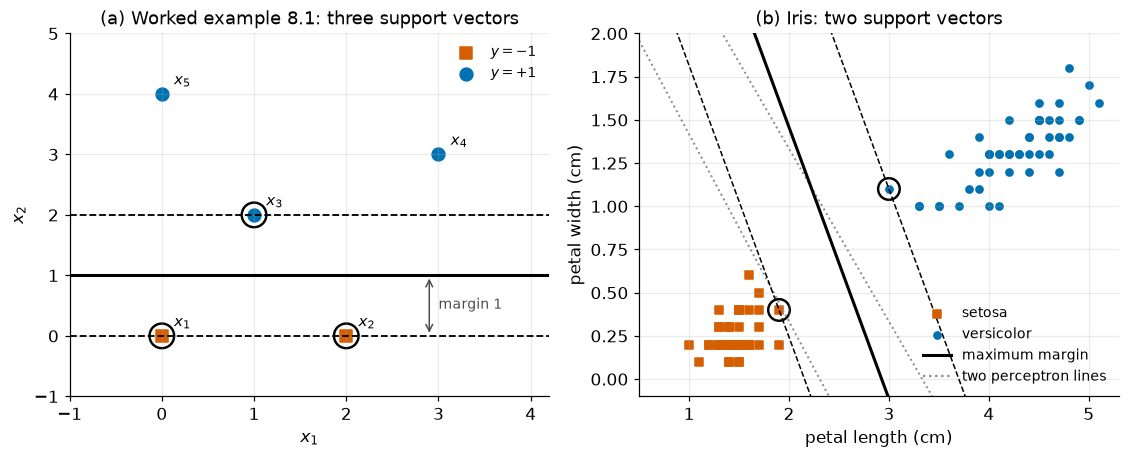

In [6]:
# Figure 8.1 — the maximum-margin hyperplane: a constructed example and a real one
def figure_8_1():
    def draw_line(ax, w, b, level, **kw):
        xs = np.array(ax.get_xlim())
        if abs(w[1]) > 1e-12:
            ax.plot(xs, (level - b - w[0] * xs) / w[1], **kw)
        else:
            ax.axvline((level - b) / w[0], **kw)

    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.3))
    ax = axes[0]
    ax.set_xlim(-1, 4.2), ax.set_ylim(-1, 5)
    ax.scatter(*X_we[y_we == -1].T, s=70, color=VERMILION, marker="s", label="$y = -1$")
    ax.scatter(*X_we[y_we == 1].T, s=70, color=BLUE, marker="o", label="$y = +1$")
    ax.scatter(*X_we[hard_we.support_].T, s=260, facecolors="none", edgecolors="k", linewidths=1.6)
    w_, b_ = hard_we.coef_.ravel(), hard_we.intercept_[0]
    draw_line(ax, w_, b_, 0, color="k", lw=2)
    draw_line(ax, w_, b_, 1, color="k", lw=1.2, ls="--")
    draw_line(ax, w_, b_, -1, color="k", lw=1.2, ls="--")
    for i, (px, py) in enumerate(X_we):
        ax.annotate(f"$x_{i + 1}$", (px, py), textcoords="offset points", xytext=(8, 6), fontsize=10)
    ax.annotate("", xy=(2.9, 0.0 + 1.0), xytext=(2.9, 0.0), arrowprops=dict(arrowstyle="<->", color="0.3"))
    ax.text(3.0, 0.45, "margin 1", fontsize=9, color="0.3")
    ax.set(xlabel="$x_1$", ylabel="$x_2$", title="(a) Worked example 8.1: three support vectors")
    ax.legend(frameon=False, loc="upper right", fontsize=9)

    ax = axes[1]
    ax.set_xlim(0.5, 5.3), ax.set_ylim(-0.1, 2.0)
    ax.scatter(*X_ir[y_ir == -1].T, s=22, color=VERMILION, marker="s", label="setosa")
    ax.scatter(*X_ir[y_ir == 1].T, s=22, color=BLUE, marker="o", label="versicolor")
    ax.scatter(*X_ir[hard_ir.support_].T, s=200, facecolors="none", edgecolors="k", linewidths=1.6)
    for p in perceptrons:
        draw_line(ax, p.coef_.ravel(), p.intercept_[0], 0, color="0.55", lw=1.3, ls=":")
    w_, b_ = hard_ir.coef_.ravel(), hard_ir.intercept_[0]
    draw_line(ax, w_, b_, 0, color="k", lw=2, label="maximum margin")
    draw_line(ax, w_, b_, 1, color="k", lw=1.0, ls="--")
    draw_line(ax, w_, b_, -1, color="k", lw=1.0, ls="--")
    ax.plot([], [], color="0.55", ls=":", label="two perceptron lines")
    ax.set(xlabel="petal length (cm)", ylabel="petal width (cm)", title="(b) Iris: two support vectors")
    ax.legend(frameon=False, loc="lower right", fontsize=9)
    fig.tight_layout()
    plt.show()


figure_8_1()

Two support vectors, one of each class, determine the line in panel (b), and $\hat{\mathbf{w}}$ is a combination of them only: the other 98 flowers could be removed from the data set without changing the classifier. The numbers above verify the statements of Theorem 8.2 on this real problem: the vector $\hat{\mathbf{w}}$ found by minimizing the primal with a general-purpose optimizer equals $\sum_i\alpha_iy_i\mathbf{x}_i$ computed from the dual coefficients of the solver of scikit-learn, $\sum_i\alpha_iy_i = 0$, and $\lVert\mathbf{w}\rVert^2 = \sum_i\alpha_i$. The support vectors are the two flowers closest to the other class; the width of the empty strip between the classes is $1.30$ cm.

:::{admonition} How this relates to Section 7.7.3
:class: note
Section 7.7.3 computed the same hard-margin direction on the *standardized* petal measurements by running gradient descent for $10^6$ steps, and found that its two active examples were the examples with indices 43 and 98 (counting from 0, as Python does). The two computations are not identical, for two reasons that are worth knowing. First, there the intercept was one of the coordinates of $\mathbf{w}$ and was *penalized* ($\lVert\hat{\mathbf{w}}\rVert$ included it), while the SVM of this chapter leaves $b$ out of the norm: this is also what makes the dual constraint $\sum_i\alpha_iy_i = 0$ appear. Second, the standardization changes the geometry of the plane. On the standardized data the two solutions differ by an angle of about $4^\circ$ in the space of $(b, \mathbf{w})$, with margins $0.646$ (intercept penalized) and $0.658$ (intercept free), and the same two support vectors; in the original units the support vectors are the examples 44 and 98. *The maximum-margin classifier is not invariant to the scaling of the features* (Section 8.7.1).
:::

In [7]:
Z_ir = StandardScaler().fit_transform(X_ir)
A_ir = np.c_[np.ones(len(y_ir)), Z_ir]
as_in_ch7 = LinearSVC(C=1e6, loss="hinge", fit_intercept=False, dual=True, max_iter=5_000_000, tol=1e-10).fit(A_ir, y_ir)      # intercept inside the norm
free_b = SVC(kernel="linear", C=1e6, tol=1e-10).fit(Z_ir, y_ir)                                                              # intercept outside the norm
v1 = as_in_ch7.coef_.ravel()
v2 = np.r_[free_b.intercept_, free_b.coef_.ravel()]
print(f"intercept penalized (Chapter 7):  (b, w) = {v1.round(4)}, margin {1 / np.linalg.norm(v1):.4f}, active examples {np.flatnonzero(np.abs(y_ir * (A_ir @ v1) - 1) < 1e-5)}")
print(f"intercept free (this chapter):    (b, w) = {v2.round(4)}, margin {1 / np.linalg.norm(free_b.coef_):.4f}, support vectors {free_b.support_}")
print(f"angle between the two directions: {np.degrees(np.arccos(v1 @ v2 / np.linalg.norm(v1) / np.linalg.norm(v2))):.1f} degrees")

intercept penalized (Chapter 7):  (b, w) = [0.2847 1.0537 1.099 ], margin 0.6456, active examples [43 98]
intercept free (this chapter):    (b, w) = [0.319  1.1203 1.0263], margin 0.6582, support vectors [43 98]
angle between the two directions: 3.9 degrees


## 8.3 Data that cannot be separated: the soft margin

### 8.3.1 Slack variables and the hinge loss

Real data are rarely separable, and even when they are, as the Breast Cancer training set of Section 6.4.4, a hyperplane squeezed between the classes with a tiny margin can be a poor classifier (Exercise 7.10 and its solution showed it: the limit of gradient descent, the hard-margin classifier, has a *lower* test accuracy than the early-stopped iterates). The remedy is to allow some constraints to be violated, at a price. Introduce a **slack variable** $\xi_i \ge 0$ for every example, which measures by how much the constraint of example $i$ is violated, and penalize their sum:

$$
\boxed{\ \min_{\mathbf{w}, b, \boldsymbol\xi}\ \ \tfrac12\lVert\mathbf{w}\rVert^2 + C\sum_{i=1}^n\xi_i \quad\text{subject to}\quad y_i(\mathbf{w}^\top\mathbf{x}_i + b)\ \ge\ 1 - \xi_i,\quad \xi_i\ge 0.\ }
\tag{soft-margin primal}
$$

The constant $C > 0$ sets the price of a violation: a large $C$ approaches the hard-margin problem, a small $C$ tolerates many violations in exchange for a wider margin. An example with $\xi_i = 0$ is on the right side of its margin hyperplane; with $0 < \xi_i \le 1$ it is inside the strip but still correctly classified; with $\xi_i > 1$ it is misclassified. For fixed $(\mathbf{w}, b)$ the smallest feasible slack is the amount by which the constraint fails, $\xi_i = \max\{0,\ 1 - y_i(\mathbf{w}^\top\mathbf{x}_i + b)\}$, and substituting it gives an *unconstrained* problem.

:::{admonition} Proposition 8.3 (the soft-margin SVM is regularized hinge-loss minimization)
:class: tip
Define the **hinge loss** of a margin $m = y\,f(\mathbf{x})$ as $\ell_{\text{hinge}}(m) = \max\{0,\ 1 - m\}$. The soft-margin problem is equivalent to

$$
\min_{\mathbf{w}, b}\ \ \frac1n\sum_{i=1}^n\ell_{\text{hinge}}\big(y_i(\mathbf{w}^\top\mathbf{x}_i + b)\big) + \frac\lambda2\lVert\mathbf{w}\rVert^2,
\qquad
\boxed{\ \lambda = \frac{1}{C\,n}\ }
$$

in the sense that both have the same minimizers (the objective of the first is $Cn$ times the objective of the second).
:::

*Proof.* For fixed $(\mathbf{w}, b)$ the slacks enter the objective of the primal with a positive coefficient and are constrained from below by $\xi_i\ge 0$ and $\xi_i\ge 1 - y_if(\mathbf{x}_i)$, so the minimum over $\boldsymbol\xi$ is attained at $\xi_i = \max\{0, 1 - y_if(\mathbf{x}_i)\}$ and the objective becomes $\tfrac12\lVert\mathbf{w}\rVert^2 + C\sum_i\ell_{\text{hinge}}(m_i)$. Dividing by $Cn$ gives the second form. $\square$

This is the same relation as in Section 6.5.1 ($\lambda = 1/(Cn)$), and it makes the point of the chapter in one line: **the SVM is a regularized linear classifier, exactly like the ridge-penalized logistic regression, with the hinge loss in place of the logistic loss.** The two losses are compared in Section 8.4. Everything that Chapter 6 said about $C$ holds here: small $C$ is strong regularization, a wide margin and a rigid model; large $C$ is weak regularization, a narrow margin and a flexible model; and $C$ must be chosen with the protocols of Chapter 5.

### 8.3.2 The dual problem and the three kinds of examples

The dual of the soft-margin problem differs from that of Theorem 8.2 in a single place: the multipliers are bounded above by $C$.

:::{admonition} Theorem 8.4 (dual problem and KKT conditions of the soft-margin SVM)
:class: tip
The soft-margin primal has a solution and the dual problem

$$
\max_{\boldsymbol\alpha}\ \ \sum_{i=1}^n\alpha_i - \frac12\sum_{i,j}\alpha_i\alpha_j\,y_iy_j\,\mathbf{x}_i^\top\mathbf{x}_j
\qquad\text{subject to}\qquad 0\le\alpha_i\le C,\quad \sum_{i=1}^n\alpha_iy_i = 0
$$

has the same optimal value. A primal solution is $\hat{\mathbf{w}} = \sum_i\hat\alpha_iy_i\mathbf{x}_i$, and with the margins $m_i = y_i(\hat{\mathbf{w}}^\top\mathbf{x}_i + \hat b)$ the optimality conditions are

$$
\hat\alpha_i = 0\ \Rightarrow\ m_i\ge 1,
\qquad
0 < \hat\alpha_i < C\ \Rightarrow\ m_i = 1,
\qquad
\hat\alpha_i = C\ \Rightarrow\ m_i\le 1,
$$

and these implications are also sufficient. The examples are thus of **three kinds**: those *beyond the margin* ($\alpha_i = 0$, which do not enter $\hat{\mathbf{w}}$), those *exactly on the margin* ($0 < \alpha_i < C$, the **free** support vectors), and those *on or inside the margin or misclassified* ($\alpha_i = C$, the **bounded** support vectors, with slack $\xi_i = 1 - m_i \ge 0$). The intercept is obtained from the free support vectors, $\hat b = y_k - \hat{\mathbf{w}}^\top\mathbf{x}_k$ for any free $k$.
:::

:::{admonition} Proof
:class: dropdown
Attach multipliers $\alpha_i\ge 0$ to the constraints $y_if(\mathbf{x}_i) - 1 + \xi_i\ge 0$ and $\mu_i\ge 0$ to $\xi_i\ge 0$:

$$
\mathcal{L} = \tfrac12\lVert\mathbf{w}\rVert^2 + C\sum_i\xi_i - \sum_i\alpha_i\big[y_i(\mathbf{w}^\top\mathbf{x}_i + b) - 1 + \xi_i\big] - \sum_i\mu_i\xi_i .
$$

The derivatives with respect to $\mathbf{w}$ and $b$ give, as before, $\mathbf{w} = \sum_i\alpha_iy_i\mathbf{x}_i$ and $\sum_i\alpha_iy_i = 0$. The derivative with respect to $\xi_i$ is $C - \alpha_i - \mu_i = 0$, and since $\mu_i\ge 0$ this means $\alpha_i\le C$ (and $\mu_i = C - \alpha_i$). Substituting, the terms in $\xi_i$ cancel exactly ($C\xi_i - \alpha_i\xi_i - \mu_i\xi_i = 0$) and we obtain the same dual function as in Theorem 8.2, now with the box constraint $0\le\alpha_i\le C$. The primal is a convex quadratic program with affine constraints and is feasible (take $\mathbf{w} = \mathbf{0}$, $b = 0$, $\xi_i = 1$), so strong duality holds and the complementary slackness conditions are $\alpha_i[\,y_if(\mathbf{x}_i) - 1 + \xi_i] = 0$ and $\mu_i\xi_i = (C - \alpha_i)\xi_i = 0$. If $\alpha_i = 0$ then $\mu_i = C > 0$, so $\xi_i = 0$ and the constraint gives $m_i\ge 1$. If $0 < \alpha_i < C$ then $\mu_i > 0$ forces $\xi_i = 0$, and $\alpha_i > 0$ forces the constraint to be active: $m_i = 1$. If $\alpha_i = C$ then the constraint is active, $m_i = 1 - \xi_i\le 1$. The sufficiency is the converse of the argument. $\square$
:::

For $C\to\infty$ the box constraint disappears and the dual becomes the dual of Theorem 8.2. When the data are separable the limit is reached at a *finite* $C$: if $C_0$ is the largest multiplier of the hard-margin solution, every $C\ge C_0$ gives exactly the same classifier (Exercise 8.4); below $C_0$ the box constraint becomes active and the solution changes. The cells below show the soft margin on two real problems. The first is the two Iris species that overlap, versicolor and virginica (petal length and width in centimeters), where no hyperplane separates the classes.

In [8]:
mask_vv = iris.target > 0                                                # versicolor (1) and virginica (2)
X_vv = iris.data[mask_vv][:, 2:4]
y_vv = 2.0 * (iris.target[mask_vv] - 1) - 1                              # -1 = versicolor, +1 = virginica

rows, models_vv = [], {}
for C in [0.01, 0.1, 1, 10, 100]:
    m_ = SVC(kernel="linear", C=C, tol=1e-8).fit(X_vv, y_vv)
    models_vv[C] = m_
    alpha_ = np.abs(m_.dual_coef_.ravel())
    margins_ = y_vv * m_.decision_function(X_vv)
    rows.append({"C": C, "margin width 2/||w||": 2 / np.linalg.norm(m_.coef_), "support vectors": len(m_.support_),
                 "alpha = C": int(np.sum(alpha_ >= C - 1e-8)), "0 < alpha < C": int(np.sum(alpha_ < C - 1e-8)),
                 "margin violators": int(np.sum(margins_ < 1 - 1e-6)), "training errors": int(np.sum(margins_ <= 0))})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

      C  margin width 2/||w||  support vectors  alpha = C  0 < alpha < C  margin violators  training errors
  0.010                 3.230               94         92              2                91                8
  0.100                 1.312               50         47              3                47                6
  1.000                 0.637               24         21              3                23                5
 10.000                 0.360               15         11              4                14                5
100.000                 0.224               12          9              3                 8                6


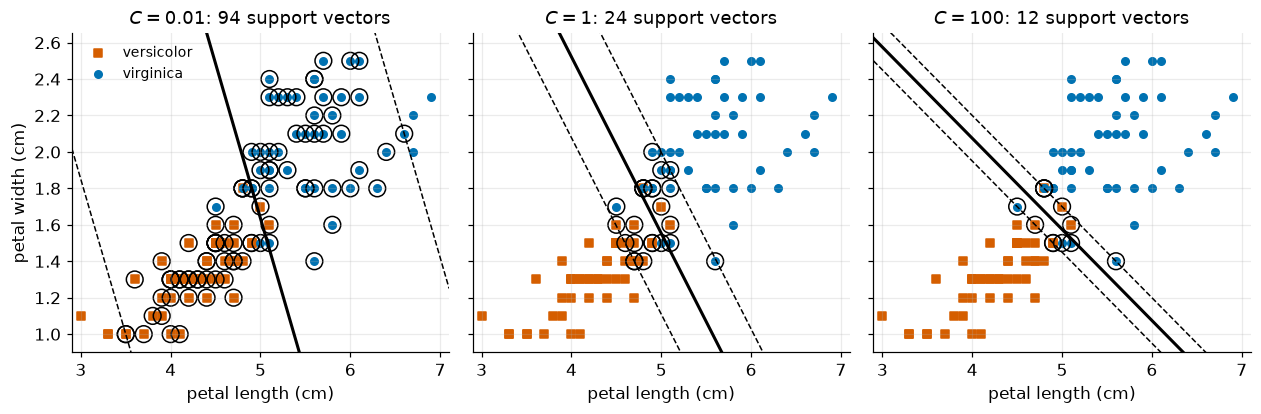

In [9]:
# Figure 8.2 — the soft margin on Iris versicolor/virginica, for three values of C
def figure_8_2():
    fig, axes = plt.subplots(1, 3, figsize=(11.6, 3.9), sharex=True, sharey=True)
    xs = np.array([2.9, 7.1])
    for ax, C in zip(axes, [0.01, 1, 100]):
        m_ = models_vv[C]
        w_, b_ = m_.coef_.ravel(), m_.intercept_[0]
        ax.scatter(*X_vv[y_vv == -1].T, s=24, color=VERMILION, marker="s", label="versicolor")
        ax.scatter(*X_vv[y_vv == 1].T, s=24, color=BLUE, marker="o", label="virginica")
        ax.scatter(*X_vv[m_.support_].T, s=120, facecolors="none", edgecolors="k", linewidths=1.0)
        ax.plot(xs, (-b_ - w_[0] * xs) / w_[1], color="k", lw=2)
        for level in (1, -1):
            ax.plot(xs, (level - b_ - w_[0] * xs) / w_[1], color="k", lw=1.0, ls="--")
        ax.set(xlim=(2.9, 7.1), ylim=(0.9, 2.65), xlabel="petal length (cm)",
               title=f"$C = {C:g}$: {len(m_.support_)} support vectors")
    axes[0].set_ylabel("petal width (cm)")
    axes[0].legend(frameon=False, loc="upper left", fontsize=9)
    fig.tight_layout()
    plt.show()


figure_8_2()

The progression is the one of Chapter 6. With a small $C$ the margin is wide, nearly all the examples are inside it (they are support vectors with $\alpha_i = C$) and the line is determined by the bulk of the data. With a large $C$ the margin shrinks around a few examples near the boundary, the number of support vectors falls, and the line follows the overlap region more closely. *The support vectors are not only the examples that are "hard", but all those that are on or beyond the wrong side of their margin: for a small $C$ they are the majority.* The number of support vectors is a measure of the complexity of the solution, as we shall see in Section 8.6.

The second problem is the Breast Cancer training set, standardized, with $C = 1$ (the value that Section 6.5 selected for the logistic regression). The cell checks the conditions of Theorem 8.4, computes the primal objective $\tfrac12\lVert\mathbf{w}\rVert^2 + C\sum_i\xi_i$ and the dual objective $\sum_i\alpha_i - \tfrac12\lVert\mathbf{w}\rVert^2$ from the solution of the solver, and shows what happens at the transition to the hard margin.

In [10]:
bc = load_breast_cancer(as_frame=True)
Xb = bc.data.to_numpy()
yb = (1 - bc.target).to_numpy().astype(int)                              # malignant = 1, as in Chapters 6 and 7
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.25, random_state=SEED, stratify=yb)
scaler_b = StandardScaler().fit(Xb_tr)
Zb, Zb_te = scaler_b.transform(Xb_tr), scaler_b.transform(Xb_te)
sb, sb_te = 2.0 * yb_tr - 1, 2.0 * yb_te - 1                             # labels in {-1, +1}
n_b = len(sb)
print(f"Breast Cancer: {n_b} training patients, {Zb.shape[1]} features (standardized), {len(sb_te)} test patients; malignant = +1")


def dual_variables(model, n):
    alpha = np.zeros(n)
    alpha[model.support_] = np.abs(model.dual_coef_.ravel())
    return alpha


C_b = 1.0
svm_b = SVC(kernel="linear", C=C_b, tol=1e-9).fit(Zb, sb)
alpha_b = dual_variables(svm_b, n_b)
m_b = sb * svm_b.decision_function(Zb)                                   # margins y_i f(x_i)
w_b = svm_b.coef_.ravel()
kinds = {"alpha = 0 (beyond the margin)": alpha_b <= 1e-9,
         "0 < alpha < C (on the margin)": (alpha_b > 1e-9) & (alpha_b < C_b - 1e-6),
         "alpha = C (inside, or misclassified)": alpha_b >= C_b - 1e-6}
rows = [{"kind": k, "examples": int(v.sum()), "smallest margin": m_b[v].min(), "largest margin": m_b[v].max(), "misclassified": int((m_b[v] <= 0).sum())}
        for k, v in kinds.items()]
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
slack = np.maximum(0, 1 - m_b)
primal_value = 0.5 * w_b @ w_b + C_b * slack.sum()
dual_value = alpha_b.sum() - 0.5 * w_b @ w_b
print(f"primal objective {primal_value:.6f}, dual objective {dual_value:.6f}; sum of alpha_i y_i = {alpha_b @ sb:.1e}; "
      f"test accuracy {np.mean(np.sign(svm_b.decision_function(Zb_te)) == sb_te):.4f}")

hard_b = SVC(kernel="linear", C=1e6, tol=1e-9).fit(Zb, sb)
C0 = np.abs(hard_b.dual_coef_).max()
print(f"hard margin: {len(hard_b.support_)} support vectors, ||w|| = {np.linalg.norm(hard_b.coef_):.3f}, largest multiplier C0 = {C0:.2f}")
for factor in [0.25, 0.5, 0.9, 1.0, 1.1, 10]:
    m_ = SVC(kernel="linear", C=factor * C0, tol=1e-9).fit(Zb, sb)
    diff = np.linalg.norm(m_.coef_ - hard_b.coef_) / np.linalg.norm(hard_b.coef_)
    print(f"  C = {factor:>4} * C0 = {factor * C0:7.2f}: ||w|| = {np.linalg.norm(m_.coef_):7.3f}, relative distance from the hard-margin w = {diff:.1e}")

Breast Cancer: 426 training patients, 30 features (standardized), 143 test patients; malignant = +1


                                kind  examples  smallest margin  largest margin  misclassified
       alpha = 0 (beyond the margin)       390           1.0178         31.4852              0
       0 < alpha < C (on the margin)        20           1.0000          1.0000              0
alpha = C (inside, or misclassified)        16          -3.0974          0.8699              4
primal objective 19.030271, dual objective 19.030267; sum of alpha_i y_i = -1.8e-15; test accuracy 0.9580
hard margin: 24 support vectors, ||w|| = 28.408, largest multiplier C0 = 125.01
  C = 0.25 * C0 =   31.25: ||w|| =  13.629, relative distance from the hard-margin w = 5.9e-01
  C =  0.5 * C0 =   62.51: ||w|| =  19.777, relative distance from the hard-margin w = 3.8e-01
  C =  0.9 * C0 =  112.51: ||w|| =  26.801, relative distance from the hard-margin w = 7.6e-02
  C =  1.0 * C0 =  125.01: ||w|| =  28.408, relative distance from the hard-margin w = 7.8e-12
  C =  1.1 * C0 =  137.51: ||w|| =  28.408, relative 

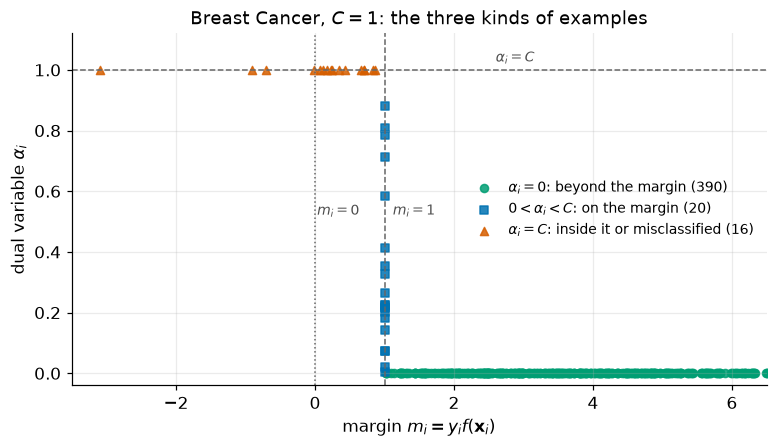

In [11]:
# Figure 8.3 — the dual variables against the margins, Breast Cancer, C = 1
def figure_8_3():
    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    styles = [("alpha = 0 (beyond the margin)", GREEN, "o"), ("0 < alpha < C (on the margin)", BLUE, "s"), ("alpha = C (inside, or misclassified)", VERMILION, "^")]
    labels = [r"$\alpha_i = 0$: beyond the margin", r"$0 < \alpha_i < C$: on the margin", r"$\alpha_i = C$: inside it or misclassified"]
    for (k, color, marker), lab in zip(styles, labels):
        v = kinds[k]
        ax.scatter(m_b[v], alpha_b[v], s=28, color=color, marker=marker, label=f"{lab} ({v.sum()})", alpha=0.85)
    ax.axvline(1, color="0.4", lw=1, ls="--")
    ax.axvline(0, color="0.4", lw=1, ls=":")
    ax.axhline(C_b, color="0.4", lw=1, ls="--")
    ax.text(1.12, 0.52, "$m_i = 1$", fontsize=9, color="0.3")
    ax.text(0.03, 0.52, "$m_i = 0$", fontsize=9, color="0.3")
    ax.text(2.6, C_b + 0.025, "$\\alpha_i = C$", fontsize=9, color="0.3")
    ax.set(xlabel=r"margin $m_i = y_i f(\mathbf{x}_i)$", ylabel=r"dual variable $\alpha_i$", xlim=(-3.5, 6.5), ylim=(-0.04, 1.12),
           title="Breast Cancer, $C = 1$: the three kinds of examples")
    ax.legend(frameon=False, fontsize=9, loc="center right")
    fig.tight_layout()
    plt.show()


figure_8_3()

The 426 patients fall in the three kinds of Theorem 8.4 exactly as stated: **390 are beyond the margin** ($\alpha_i = 0$; the smallest margin among them is $1.018$ and the largest $31.5$), **20 are exactly on it** ($0 < \alpha_i < C$; all with margin $1.0000$), and **16 have $\alpha_i = C$**, with margins from $-3.10$ to $0.87$, four of them misclassified. So $36$ of the $426$ examples ($8.5\%$) determine $\hat{\mathbf{w}}$, and $390$ could be deleted without changing the classifier. The primal and dual objectives agree ($19.0303$ and $19.0303$, up to the tolerance of the solver) and $\sum_i\alpha_iy_i = 0$. The test accuracy is $0.958$ ($6$ errors among $143$ patients). The last lines show the transition to the hard margin: its solution has $24$ support vectors and $\lVert\hat{\mathbf{w}}\rVert = 28.4$, the value that appeared in Exercise 7.10 (there the intercept was part of the norm), and its largest multiplier is $C_0 = 125$. **For every $C\ge C_0$ the soft-margin solution is exactly the hard-margin one** (relative distance $10^{-11}$ or zero), while at $0.9\,C_0$ it is already $8\%$ away and at $C_0/4$, $59\%$ away, with a norm of $13.6$. The value $C = 1$ that works well in practice is two orders of magnitude below $C_0$ and has $\lVert\mathbf{w}\rVert = 2.7$: the hard margin is the far end of a path, not the typical SVM.

## 8.4 The hinge loss, and what it estimates

### 8.4.1 Four losses of the margin

All the classifiers of Chapters 6 to 8 minimize an average of a loss of the margin $m = y\,f(\mathbf{x})$ plus a penalty, and differ only in the loss. Figure 8.4 draws four of them as functions of $m$: the 0–1 loss $\mathbb{I}[m\le 0]$ that we would like to minimize but cannot (it is not convex, nor continuous), the hinge loss $\max\{0, 1 - m\}$ of this chapter, its square $\max\{0, 1 - m\}^2$ (the loss of `LinearSVC` by default, which is differentiable), and the logistic loss $\log_2(1 + e^{-m})$ of Chapter 6 (divided by $\ln 2$ so that it passes through the point $(0, 1)$ like the others).

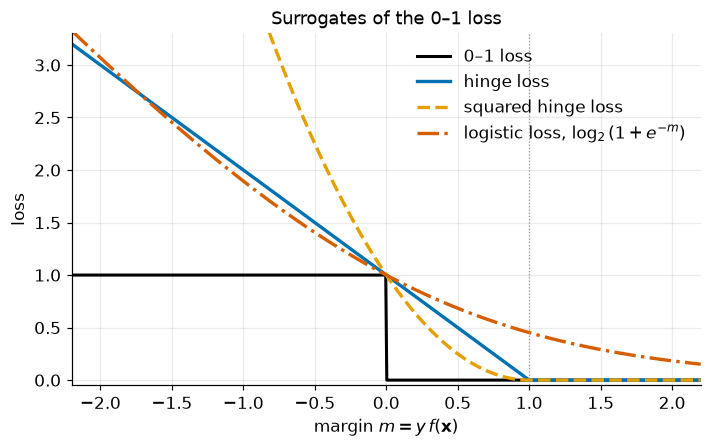

In [12]:
# Figure 8.4 — four losses as functions of the margin
def figure_8_4():
    m = np.linspace(-2.2, 2.2, 600)
    fig, ax = plt.subplots(figsize=(6.6, 4.2))
    ax.plot(m, (m <= 0).astype(float), color="k", lw=2, label="0–1 loss")
    ax.plot(m, np.maximum(0, 1 - m), color=BLUE, lw=2.2, label="hinge loss")
    ax.plot(m, np.maximum(0, 1 - m) ** 2, color=ORANGE, lw=2.2, ls="--", label="squared hinge loss")
    ax.plot(m, np.log2(1 + np.exp(-m)), color=VERMILION, lw=2.2, ls="-.", label=r"logistic loss, $\log_2(1 + e^{-m})$")
    ax.axvline(1, color="0.6", lw=0.8, ls=":")
    ax.set(xlabel=r"margin $m = y\,f(\mathbf{x})$", ylabel="loss", xlim=(-2.2, 2.2), ylim=(-0.05, 3.3), title="Surrogates of the 0–1 loss")
    ax.legend(frameon=False, loc="upper right")
    fig.tight_layout()
    plt.show()


figure_8_4()

The hinge, the squared hinge and the logistic loss are convex upper bounds of the 0–1 loss, which makes them tractable surrogates (the hinge loss is the one that appears in the margin bound of Section 3.8.4 through the ramp loss $\varphi_\gamma$, which it dominates). The difference that matters is at the right of the plot: the hinge loss is **exactly zero** for $m\ge 1$, so an example that is well classified with a margin of at least one has no influence on the solution (it has $\alpha_i = 0$), while the logistic loss is positive for every margin and every example keeps pulling on the weights, ever more weakly. This is the origin of the sparsity of the SVM. To compare the two precisely, return to the stationarity condition of the regularized logistic regression of Section 6.5, written in the scikit-learn parametrization where the objective is $\tfrac12\lVert\mathbf{w}\rVert^2 + C\sum_i\log(1 + e^{-m_i})$. Setting the gradient in $\mathbf{w}$ and in $b$ to zero gives

$$
\mathbf{w} = \sum_{i=1}^n\alpha_i\,y_i\,\mathbf{x}_i,
\qquad
\sum_{i=1}^n\alpha_iy_i = 0,
\qquad
\boxed{\ \alpha_i^{\text{logistic}} = C\,\sigma(-m_i)\ }
$$

with $\sigma$ the sigmoid. **The logistic regression has the same representation as the SVM**, as a combination of the training examples with weights $\alpha_i\in(0, C)$ and $\sum_i\alpha_iy_i = 0$; the difference is only the rule that gives the weights. For the hinge loss the rule is $\alpha_i = C$ if $m_i < 1$, $\alpha_i = 0$ if $m_i > 1$ and $\alpha_i\in[0, C]$ if $m_i = 1$: a *step function* of the margin, which is a hardened version of the *smooth* sigmoid $C\sigma(-m_i)$. We can check the identity on the Breast Cancer data.

In [13]:
logit_b = LogisticRegression(C=C_b, tol=1e-12, max_iter=100_000).fit(Zb, yb_tr)
w_l, b_l = logit_b.coef_.ravel(), logit_b.intercept_[0]
m_l = sb * (Zb @ w_l + b_l)
alpha_l = C_b / (1 + np.exp(m_l))                                         # C * sigmoid(-m_i)
print(f"logistic regression, C = {C_b}: largest |w - sum alpha_i y_i x_i| = {np.abs(w_l - (alpha_l * sb) @ Zb).max():.1e}, sum alpha_i y_i = {alpha_l @ sb:.1e}")
cosine = w_b @ w_l / (np.linalg.norm(w_b) * np.linalg.norm(w_l))
print(f"cosine between the SVM weights and the logistic weights: {cosine:.4f};  norms {np.linalg.norm(w_b):.3f} and {np.linalg.norm(w_l):.3f}")
print(f"examples with a non-zero multiplier: SVM {int((alpha_b > 1e-9).sum())} of {n_b};  "
      f"logistic: {int((alpha_l > 1e-3 * C_b).sum())} with alpha_i > 0.001 C, {int((alpha_l > 1e-6 * C_b).sum())} with alpha_i > 1e-6 C, {int((alpha_l > 0).sum())} with alpha_i > 0")
print(f"test accuracy: SVM {np.mean(np.sign(svm_b.decision_function(Zb_te)) == sb_te):.4f}, logistic {logit_b.score(Zb_te, yb_te):.4f}")

logistic regression, C = 1.0: largest |w - sum alpha_i y_i x_i| = 2.0e-06, sum alpha_i y_i = -9.8e-07
cosine between the SVM weights and the logistic weights: 0.9189;  norms 2.712 and 3.764
examples with a non-zero multiplier: SVM 36 of 426;  logistic: 228 with alpha_i > 0.001 C, 387 with alpha_i > 1e-6 C, 426 with alpha_i > 0
test accuracy: SVM 0.9580, logistic 0.9650


The identity holds to the precision of the solver ($2\cdot 10^{-6}$): the regularized logistic regression is also a combination of training examples with $\sum_i\alpha_iy_i = 0$, but **no multiplier is exactly zero**. For the same $C = 1$ the logistic regression has $228$ examples with $\alpha_i > 0.001\,C$ and $387$ with $\alpha_i > 10^{-6}C$, against $36$ for the SVM ($20$ free and $16$ bounded). The two weight vectors point in similar directions (cosine $0.919$; norms $2.71$ for the SVM and $3.76$ for the logistic regression) and give the same kind of accuracy on the test set, $0.958$ and $0.965$ ($6$ and $5$ errors among $143$ patients). The difference between the two methods is therefore not in what they can express but in how the training set is used: the SVM needs only its support vectors, which gives a compact model and the leave-one-out bound of Section 8.6, while the logistic regression keeps a small weight on every example and delivers probabilities. When the data are separable and $C\to\infty$, the direction of the logistic solution converges to the hard-margin direction (Section 7.7.3 reached it from the side of gradient descent), because the margins of the non-support examples grow, so that their weights $C\sigma(-m_i)$ vanish.

### 8.4.2 What the hinge loss estimates

Chapter 6 chose the logistic loss because it is the negative log-likelihood of a model of the conditional probability, and the classifier it produces estimates $\eta(\mathbf{x}) = \mathbb{P}(y = 1\mid\mathbf{x})$ (through $\sigma(f(\mathbf{x}))$). The hinge loss has no such interpretation, and the next result says what it does instead. Let $f$ be an arbitrary function of $\mathbf{x}$ (not necessarily linear), and write $\eta(\mathbf{x}) = \mathbb{P}(y = +1\mid\mathbf{x})$, as in Chapter 3, so that the Bayes classifier is $\operatorname{sign}(\eta(\mathbf{x}) - \tfrac12)$.

:::{admonition} Proposition 8.5 (the population minimizer of the hinge loss is the Bayes classifier)
:class: tip
For every $\mathbf{x}$ with $\eta(\mathbf{x})\ne\tfrac12$, the value $f(\mathbf{x})$ that minimizes the conditional expected hinge loss $\eta\,\ell_{\text{hinge}}(f) + (1 - \eta)\,\ell_{\text{hinge}}(-f)$ is $f^\ast(\mathbf{x}) = \operatorname{sign}(2\eta(\mathbf{x}) - 1)$: **the hinge loss estimates the Bayes classifier directly and not the probability.** For comparison, the minimizer of the logistic loss $\log(1 + e^{-m})$ is $f^\ast = \ln\frac{\eta}{1 - \eta}$ (the log-odds) and that of the squared hinge loss is $f^\ast = 2\eta - 1$ for $\eta \in [0, 1]$ (Exercise 8.3).
:::

:::{admonition} Proof
:class: dropdown
Fix $\mathbf{x}$ and write $\eta$ for $\eta(\mathbf{x})$ and $g(f) = \eta\max\{0, 1 - f\} + (1 - \eta)\max\{0, 1 + f\}$. For $f\in[-1, 1]$ both maxima are linear: $g(f) = \eta(1 - f) + (1 - \eta)(1 + f) = 1 + (1 - 2\eta)f$, which is decreasing in $f$ when $\eta > \tfrac12$ (and increasing when $\eta < \tfrac12$). For $f > 1$ we have $g(f) = (1 - \eta)(1 + f)$, increasing in $f$, and for $f < -1$ we have $g(f) = \eta(1 - f)$, decreasing in $f$. Thus if $\eta > \tfrac12$ the function $g$ decreases on $(-\infty, 1]$ and increases on $[1, \infty)$, and its unique minimizer is $f = 1$, with value $2(1 - \eta)$. The case $\eta < \tfrac12$ is symmetric and gives $f = -1$. $\square$
:::

Two consequences. First, the Bayes classifier is the best classifier of Chapter 3 (the minimizer of the 0–1 risk), and the hinge loss reaches it in the limit of a rich enough class and of unlimited data: a surrogate with this property is called **classification-calibrated**, and Zhang (2004) shows that the excess 0–1 risk is bounded by the excess hinge risk, $\mathcal{R}(f) - \mathcal{R}^\ast\le\mathcal{R}_{\text{hinge}}(f) - \mathcal{R}^\ast_{\text{hinge}}$. Second, the *score* of an SVM is not a probability: it is a distance to the hyperplane, whose size depends on $C$, and since $f^\ast$ takes the value $\pm 1$ whatever the confidence, the scores carry no calibrated information about $\eta$. If probabilities are needed they must be added in a second step (Platt scaling, Section 8.7.3), by the recalibration of Section 5.6.4.

## 8.5 Solving the SVM

The SVM is a convex quadratic program, and a general-purpose solver could handle it, as in the cells above for the primal. The structure of the problem allows much better algorithms, which we derive and implement from scratch in this section. They belong to the two families of Chapter 7: a first-order method on the primal (the hinge loss is not differentiable, so it needs *subgradients*), and a coordinate method on the dual (where the constraints are simple boxes).

### 8.5.1 The subgradient method

The hinge loss has a kink at $m = 1$, and the theorems of Chapter 7, which assume an $L$-smooth function, do not apply. A **subgradient** of a convex function $f$ at $\mathbf{w}$ is any vector $\mathbf{g}$ with $f(\mathbf{v})\ge f(\mathbf{w}) + \mathbf{g}^\top(\mathbf{v} - \mathbf{w})$ for all $\mathbf{v}$; at a point where $f$ is differentiable it is the gradient, and at a kink it is any slope between the left and right derivatives. For the objective $f(\mathbf{w}) = \frac1n\sum_i\max\{0, 1 - y_i\mathbf{w}^\top\mathbf{x}_i\} + \frac\lambda2\lVert\mathbf{w}\rVert^2$ a subgradient is

$$
\mathbf{g}(\mathbf{w}) = \lambda\mathbf{w} - \frac1n\sum_{i\,:\,y_i\mathbf{w}^\top\mathbf{x}_i < 1}y_i\mathbf{x}_i,
$$

which differs from a gradient only through the convention at the kinks (we take $0$ for the examples with margin exactly $1$). It is the same "features times residual" structure as in Chapter 7, with a residual that is $1$ for the examples inside the margin and $0$ for the others. To have a *strongly convex* objective we put the intercept inside $\mathbf{w}$ (as a constant feature) and therefore penalize it; this is the form that `LinearSVC` solves, and Section 8.5.3 comments on the difference.

:::{admonition} Theorem 8.6 (the subgradient method with step $1/(\lambda k)$)
:class: tip
Let $f$ be $\lambda$-strongly convex on a closed convex set $\Omega$, with minimizer $\mathbf{w}^\ast\in\Omega$, and let $\mathbf{w}_{k+1} = \Pi_\Omega\big(\mathbf{w}_k - \eta_k\mathbf{g}_k\big)$ with $\mathbf{g}_k\in\partial f(\mathbf{w}_k)$ (where $\Pi_\Omega$ is the projection on $\Omega$), the step $\eta_k = 1/(\lambda k)$, and $\lVert\mathbf{g}_k\rVert\le G$ for all $k$. Then for every $K\ge 1$

$$
\frac1K\sum_{k=1}^K f(\mathbf{w}_k) - f(\mathbf{w}^\ast)\ \le\ \frac{G^2\,(1 + \ln K)}{2\lambda K},
$$

and, by convexity, the same bound holds for the average iterate $\bar{\mathbf{w}}_K = \frac1K\sum_{k\le K}\mathbf{w}_k$: $f(\bar{\mathbf{w}}_K) - f(\mathbf{w}^\ast)\le G^2(1 + \ln K)/(2\lambda K)$.
:::

:::{admonition} Proof
:class: dropdown
Write $a_k = \lVert\mathbf{w}_k - \mathbf{w}^\ast\rVert^2$. The projection does not increase the distance to a point of $\Omega$, so $a_{k+1}\le\lVert\mathbf{w}_k - \eta_k\mathbf{g}_k - \mathbf{w}^\ast\rVert^2 = a_k - 2\eta_k\mathbf{g}_k^\top(\mathbf{w}_k - \mathbf{w}^\ast) + \eta_k^2\lVert\mathbf{g}_k\rVert^2$. Strong convexity and the definition of a subgradient give $f(\mathbf{w}^\ast)\ge f(\mathbf{w}_k) + \mathbf{g}_k^\top(\mathbf{w}^\ast - \mathbf{w}_k) + \frac\lambda2a_k$, that is $\mathbf{g}_k^\top(\mathbf{w}_k - \mathbf{w}^\ast)\ge f(\mathbf{w}_k) - f(\mathbf{w}^\ast) + \frac\lambda2a_k$. Substituting and rearranging,

$$
f(\mathbf{w}_k) - f(\mathbf{w}^\ast)\ \le\ \frac{a_k - a_{k+1}}{2\eta_k} - \frac\lambda2a_k + \frac{\eta_k}{2}G^2 .
$$

With $\eta_k = 1/(\lambda k)$ the first term is $\frac{\lambda k}{2}(a_k - a_{k+1})$. Summing from $k = 1$ to $K$, the terms with $a_k$ telescope:

$$
\sum_{k=1}^K\Big[\tfrac{\lambda k}{2}(a_k - a_{k+1}) - \tfrac\lambda2a_k\Big] = \tfrac\lambda2\Big[\sum_{k=1}^Kka_k - \sum_{k=2}^{K+1}(k - 1)a_k - \sum_{k=1}^Ka_k\Big] = -\tfrac\lambda2Ka_{K+1}\ \le\ 0 .
$$

What remains is $\sum_{k\le K}[f(\mathbf{w}_k) - f(\mathbf{w}^\ast)]\le\frac{G^2}{2\lambda}\sum_{k\le K}\frac1k\le\frac{G^2}{2\lambda}(1 + \ln K)$. $\square$
:::

Compare with Chapter 7. For a smooth and strongly convex function gradient descent converges at the *linear* rate $(1 - \mu/L)^k$ (Theorem 7.5); for the non-smooth hinge loss the best that this method guarantees is $O(\ln K/K)$: the price of the kink. The stochastic version, which replaces $\mathbf{g}_k$ by the subgradient of a *single* example, $\mathbf{g}_k = \lambda\mathbf{w}_k - y_i\mathbf{x}_i\mathbb{I}[y_i\mathbf{w}_k^\top\mathbf{x}_i < 1]$, is the **Pegasos** algorithm of Shalev-Shwartz et al. (2011); the proof above holds in expectation, because the expected stochastic subgradient is a subgradient and $G^2$ bounds $\mathbb{E}\lVert\mathbf{g}_k\rVert^2$. The cost of an iteration does not depend on $n$, which is the point of Section 7.6. The bound has the typical form $\tfrac{G^2}{\lambda}\cdot\tfrac{\ln K}{K}$, in which the strong convexity $\lambda = 1/(Cn)$ appears in the denominator: *the larger $C$ and $n$, the weaker the regularization and the slower the convergence*.

To measure the rate we need the exact minimum $f^\ast$ of the problem with the intercept inside $\mathbf{w}$. We compute it with the **dual coordinate descent** of Hsieh et al. (2008), which is also the algorithm of `LinearSVC`: with the intercept in $\mathbf{w}$ the equality constraint of the dual disappears, only the boxes $0\le\alpha_i\le C$ remain, and the function of a single $\alpha_i$ (the others fixed) is a one-dimensional quadratic, whose minimizer is the Newton step clipped to the box. The cell below implements it, checks the duality gap, and then runs the subgradient method, deterministic (all the examples at each step) for $10^4$ steps and stochastic (one example) for $2\cdot 10^5$ steps. The domain is the ball of radius $\sqrt{2/\lambda}$, which contains the minimizer because $\frac\lambda2\lVert\mathbf{w}^\ast\rVert^2\le f(\mathbf{w}^\ast)\le f(\mathbf{0}) = 1$.

In [14]:
def dual_coordinate_descent(A, s, C, tol=1e-9, max_sweeps=5000, seed=SEED):
    """Dual coordinate descent for  min 1/2||w||^2 + C sum_i max(0, 1 - s_i w.a_i)  (intercept inside w): boxes only."""
    rng = np.random.default_rng(seed)
    n = len(s)
    alpha, w = np.zeros(n), np.zeros(A.shape[1])
    q = np.einsum("ij,ij->i", A, A)                                       # Q_ii = ||a_i||^2
    for sweep in range(1, max_sweeps + 1):
        for i in rng.permutation(n):
            g = s[i] * (w @ A[i]) - 1                                     # derivative of the (minimized) dual in alpha_i
            new = min(max(alpha[i] - g / q[i], 0.0), C)                   # Newton step, clipped to the box [0, C]
            w += (new - alpha[i]) * s[i] * A[i]
            alpha[i] = new
        if sweep % 10 == 0:
            primal = 0.5 * w @ w + C * np.maximum(0, 1 - s * (A @ w)).sum()
            dual = alpha.sum() - 0.5 * w @ w
            if (primal - dual) / (n * C) < tol:
                break
    return w, alpha, sweep, (primal - dual) / (n * C)


lam_b = 1 / (n_b * C_b)
A_b = np.c_[np.ones(n_b), Zb]                                             # the constant feature: the intercept is inside w (and penalized)


def f_hinge(w):
    return 0.5 * lam_b * w @ w + np.mean(np.maximum(0, 1 - sb * (A_b @ w)))


w_dcd, alpha_dcd, sweeps_dcd, gap_dcd = dual_coordinate_descent(A_b, sb, C_b)
f_star_b = f_hinge(w_dcd)
print(f"dual coordinate descent: {sweeps_dcd} sweeps, duality gap {gap_dcd:.1e}, f* = {f_star_b:.8f}, ||w*|| = {np.linalg.norm(w_dcd):.4f}, "
      f"support vectors {int((alpha_dcd > 0).sum())} ({int((alpha_dcd >= C_b - 1e-9).sum())} at the bound), lambda = {lam_b:.2e}")


def subgradient_method(T, stochastic, seed=SEED):
    rng = np.random.default_rng(seed)
    radius = np.sqrt(2 / lam_b)                                           # the minimizer lies in this ball since f(0) = 1
    w, w_avg = np.zeros(A_b.shape[1]), np.zeros(A_b.shape[1])
    checkpoints = set(np.unique(np.round(np.logspace(0, np.log10(T), 45)).astype(int))) | {10, 100, 1000, 10_000, 100_000, 200_000}
    record, g_max = [], 0.0
    for t in range(1, T + 1):
        if stochastic:
            i = rng.integers(n_b)
            g = lam_b * w - (sb[i] * A_b[i] if sb[i] * (A_b[i] @ w) < 1 else 0.0)
        else:
            viol = sb * (A_b @ w) < 1
            g = lam_b * w - (sb[viol, None] * A_b[viol]).sum(axis=0) / n_b
        g_max = max(g_max, np.linalg.norm(g))
        w = w - g / (lam_b * t)                                           # the step 1 / (lambda t) of Theorem 8.6
        norm = np.linalg.norm(w)
        if norm > radius:
            w *= radius / norm                                            # projection on the ball
        w_avg += (w - w_avg) / t                                          # running average of the iterates
        if t in checkpoints:
            record.append((t, f_hinge(w) - f_star_b, f_hinge(w_avg) - f_star_b))
    return np.array(record), g_max


rec_full, g_full = subgradient_method(10_000, stochastic=False)
rec_sgd, g_sgd = subgradient_method(200_000, stochastic=True)
print(f"largest subgradient norm met: {g_full:.2f} (deterministic), {g_sgd:.2f} (single example)")
rows = []
for T in [10, 100, 1000, 10_000]:
    r = rec_full[rec_full[:, 0] == T][0]
    rows.append({"steps": T, "deterministic: last iterate": r[1], "deterministic: average": r[2],
                 "bound of Theorem 8.6": g_full**2 * (1 + np.log(T)) / (2 * lam_b * T)})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3e}"))
rows = []
for T in [100, 1000, 10_000, 100_000, 200_000]:
    r = rec_sgd[rec_sgd[:, 0] == T][0]
    rows.append({"steps": T, "epochs": T / n_b, "stochastic: last iterate": r[1], "stochastic: average": r[2]})
print(pd.DataFrame(rows).to_string(index=False, formatters={"epochs": lambda v: f"{v:.1f}", "stochastic: last iterate": lambda v: f"{v:.3e}", "stochastic: average": lambda v: f"{v:.3e}"}))

dual coordinate descent: 2330 sweeps, duality gap 9.4e-10, f* = 0.04467453, ||w*|| = 2.7180, support vectors 35 (16 at the bound), lambda = 2.35e-03


largest subgradient norm met: 2.78 (deterministic), 19.19 (single example)
 steps  deterministic: last iterate  deterministic: average  bound of Theorem 8.6
    10                    5.055e-01               8.072e-01             5.447e+02
   100                    2.279e-03               6.094e-02             9.244e+01
  1000                    2.005e-04               3.828e-03             1.304e+01
 10000                    3.938e-05               3.705e-04             1.684e+00
 steps epochs stochastic: last iterate stochastic: average
   100    0.2                1.570e+00           8.348e-01
  1000    2.3                1.749e-01           3.512e-01
 10000   23.5                2.292e-02           3.367e-02
100000  234.7                1.921e-03           3.783e-03
200000  469.5                9.050e-04           2.061e-03


The dual coordinate descent reaches a duality gap of $10^{-9}$ (in units of $f$) after $2{,}330$ sweeps, and gives $f^\ast = 0.04467$, $\lVert\mathbf{w}^\ast\rVert = 2.72$ and $35$ support vectors ($16$ at the bound; one fewer than with the free intercept, because the intercept is now penalized). Against this exact value the tables and Figure 8.5(a) show the subgradient method. The deterministic method is $2.3\cdot 10^{-3}$ above the minimum after $100$ steps, $2.0\cdot 10^{-4}$ after $1{,}000$ and $3.9\cdot 10^{-5}$ after $10^4$ for the last iterate; the **average** of the iterates, which is the object of Theorem 8.6, is $6.1\cdot 10^{-2}$, $3.8\cdot 10^{-3}$ and $3.7\cdot 10^{-4}$ at the same steps, an order of magnitude worse because it carries the large early errors, but it decays like $1/k$ (up to the logarithm), as the theorem says. The last iterate is better here but irregular, and no theorem here covers it. The bound itself, computed with the largest subgradient norm met along the run ($2.78$), is true and **loose by three to four orders of magnitude** ($1.7$ at $k = 10^4$, against $3.7\cdot 10^{-4}$ for the average iterate and $3.9\cdot 10^{-5}$ for the last one), the typical fate of worst-case bounds, as for Theorem 7.4. The stochastic method makes one cheap step per example: its suboptimality is $1.7\cdot 10^{-1}$ after $1{,}000$ steps, $2.3\cdot 10^{-2}$ after $10^4$ ($23$ epochs), $1.9\cdot 10^{-3}$ after $10^5$ ($234$ epochs) and $9\cdot 10^{-4}$ after $2\cdot 10^5$ steps ($470$ epochs); the same decay in the number of steps but with the irregular jumps of SGD. Counted in passes over the data, the deterministic method is better on this small problem ($2.3\cdot 10^{-3}$ after $100$ epochs, against $1.9\cdot 10^{-3}$ after $234$), the conclusion of Section 7.6 for Breast Cancer: stochastic methods win when $n$ is large, not when it is $426$.

### 8.5.2 Sequential minimal optimization

The subgradient method treats the primal; it converges slowly because of the kink. The dual is a smooth quadratic program in $\boldsymbol\alpha$ with box constraints *and* the equality constraint $\sum_i\alpha_iy_i = 0$ (when the intercept is kept out of the norm). A coordinate method that moves a single $\alpha_i$ would violate the equality, so the smallest feasible move changes **two** multipliers at once. This is the idea of **sequential minimal optimization** (SMO, Platt, 1998), which underlies libsvm, and the two-variable subproblem can be solved in closed form.

Write the dual as the minimization of $D(\boldsymbol\alpha) = \frac12\boldsymbol\alpha^\top\mathbf{Q}\boldsymbol\alpha - \mathbf{1}^\top\boldsymbol\alpha$ with $Q_{ij} = y_iy_jK_{ij}$ and $K_{ij} = \mathbf{x}_i^\top\mathbf{x}_j$ (the **Gram matrix**; with other functions of $\mathbf{x}_i, \mathbf{x}_j$ in its place we obtain the kernels of Chapter 9). Let $f_0(\mathbf{x}_t) = \sum_s\alpha_sy_sK_{st}$ be the score without intercept and $e_t = y_t - f_0(\mathbf{x}_t)$. The gradient of $D$ is $\nabla_tD = y_tf_0(\mathbf{x}_t) - 1 = -y_te_t$.

:::{admonition} Proposition 8.7 (optimality and the SMO step)
:class: tip
Let $I_{\text{up}} = \{t : (y_t = 1, \alpha_t < C)\ \text{or}\ (y_t = -1, \alpha_t > 0)\}$ and $I_{\text{low}} = \{t : (y_t = 1, \alpha_t > 0)\ \text{or}\ (y_t = -1, \alpha_t < C)\}$. A feasible $\boldsymbol\alpha$ is optimal if and only if $\max_{t\in I_{\text{up}}}e_t\le\min_{t\in I_{\text{low}}}e_t$, and then any $b$ between the two values is an intercept that satisfies the KKT conditions of Theorem 8.4. If $i\in I_{\text{up}}$ and $j\in I_{\text{low}}$ violate it ($\text{gap} = e_i - e_j > 0$), the move $\alpha_i\mapsto\alpha_i + y_it$, $\alpha_j\mapsto\alpha_j - y_jt$ keeps $\sum_s\alpha_sy_s$ constant, and $D$ is minimized along it, for $t\ge 0$, at

$$
t^\ast = \min\Big\{\ \frac{e_i - e_j}{K_{ii} + K_{jj} - 2K_{ij}},\ \ t_{\max}\Big\},
$$

where $t_{\max}$ is the largest $t$ for which $\alpha_i$ and $\alpha_j$ remain in $[0, C]$. The dual objective decreases at every step in which $\text{gap} > 0$.
:::

:::{admonition} Proof
:class: dropdown
*Optimality.* The KKT conditions of Theorem 8.4 say that for some $b$: $y_t(f_0(\mathbf{x}_t) + b)\ge 1$ if $\alpha_t = 0$, $= 1$ if $0 < \alpha_t < C$, and $\le 1$ if $\alpha_t = C$. Written with $e_t = y_t - f_0(\mathbf{x}_t)$ (multiply by $y_t$, using $y_t^2 = 1$) these are: $e_t\le b$ for $y_t = 1$ and $\alpha_t < C$, and for $y_t = -1$ and $\alpha_t > 0$ (that is, for $t\in I_{\text{up}}$); $e_t\ge b$ for $t\in I_{\text{low}}$; and $e_t = b$ for the free examples (which are in both sets). Such a $b$ exists if and only if $\max_{I_{\text{up}}}e_t\le\min_{I_{\text{low}}}e_t$. *The step.* Along the direction $\mathbf{d}$ with $d_i = y_i$, $d_j = -y_j$ and all other entries zero, $\mathbf{y}^\top\mathbf{d} = y_i^2 - y_j^2 = 0$, so the equality constraint is preserved. The directional derivative of $D$ is $\nabla_iD\,y_i - \nabla_jD\,y_j = -e_i + e_j = -\text{gap} < 0$, and the curvature is $\mathbf{d}^\top\mathbf{Q}\mathbf{d} = Q_{ii} + Q_{jj} - 2y_iy_jQ_{ij} = K_{ii} + K_{jj} - 2K_{ij} = \lVert\phi(\mathbf{x}_i) - \phi(\mathbf{x}_j)\rVert^2$, which is positive for distinct points. The minimum of the quadratic $t\mapsto D(\boldsymbol\alpha + t\mathbf{d})$ is at $\text{gap}/(K_{ii} + K_{jj} - 2K_{ij})$ and, the function being convex, the minimizer on an interval of feasible values is this point clipped to the interval. The directions of the sets $I_{\text{up}}$ and $I_{\text{low}}$ are exactly those that increase $\alpha_i$ (or decrease it, according to $y_i$) without leaving the box, so $t_{\max} > 0$. $\square$
:::

Choosing the pair with the *largest violation* (the maximal $e_i$ in $I_{\text{up}}$ and the minimal $e_j$ in $I_{\text{low}}$) gives the simplest version of the algorithm, and the stopping rule is $\text{gap}\le\varepsilon$. The cell below is the whole algorithm. It works with the Gram matrix, so it will handle kernels without changes.

In [15]:
def smo(K, y, C, tol=1e-8, max_iter=500_000, record=False):
    """Sequential minimal optimization (maximal violating pair) for the SVM dual with a Gram matrix K and labels in {-1, +1}."""
    n = len(y)
    alpha, G = np.zeros(n), -np.ones(n)                                   # G = Q alpha - 1 is the gradient of the dual
    hist = []
    for it in range(1, max_iter + 1):
        e = -y * G                                                        # e_t = y_t - f_0(x_t)
        up = ((y == 1) & (alpha < C)) | ((y == -1) & (alpha > 0))
        low = ((y == 1) & (alpha > 0)) | ((y == -1) & (alpha < C))
        i = np.flatnonzero(up)[np.argmax(e[up])]
        j = np.flatnonzero(low)[np.argmin(e[low])]
        gap = e[i] - e[j]
        if record:
            hist.append((gap, 0.5 * alpha.sum() - 0.5 * alpha @ G))       # violation and dual value  sum(alpha) - 1/2 alpha Q alpha
        if gap <= tol:
            break
        a = max(K[i, i] + K[j, j] - 2 * K[i, j], 1e-12)
        t_i = (C - alpha[i]) if y[i] == 1 else alpha[i]                   # room to move alpha_i along y_i
        t_j = alpha[j] if y[j] == 1 else (C - alpha[j])                   # room to move alpha_j along -y_j
        t = min(gap / a, t_i, t_j)
        d_i, d_j = y[i] * t, -y[j] * t
        alpha[i] += d_i
        alpha[j] += d_j
        G += (y * y[i]) * K[:, i] * d_i + (y * y[j]) * K[:, j] * d_j      # update of the gradient: two columns of Q
    e = -y * G
    free = (alpha > 1e-10) & (alpha < C - 1e-10)
    if free.any():
        b = e[free].mean()                                                # e_t = b for the free support vectors
    else:
        up = ((y == 1) & (alpha < C)) | ((y == -1) & (alpha > 0))
        low = ((y == 1) & (alpha > 0)) | ((y == -1) & (alpha < C))
        b = (e[up].max() + e[low].min()) / 2
    return alpha, b, it, (np.array(hist) if record else None)


K_b = Zb @ Zb.T                                                           # linear Gram matrix of the 426 training patients
rows = []
for C in [0.01, 0.1, 1, 10, 1000]:
    t0 = time.perf_counter()
    a_, b_, iters_, _ = smo(K_b, sb, C, tol=1e-9)
    elapsed = time.perf_counter() - t0
    ref = SVC(kernel="linear", C=C, tol=1e-10).fit(Zb, sb)
    w_ = (a_ * sb) @ Zb
    rows.append({"C": C, "SMO iterations": iters_, "support vectors (SMO)": int((a_ > 1e-9).sum()), "support vectors (SVC)": len(ref.support_),
                 "rel. diff. of w": np.linalg.norm(w_ - ref.coef_.ravel()) / np.linalg.norm(ref.coef_), "|b - b_SVC|": abs(b_ - ref.intercept_[0])})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2e}" if v < 1e-2 else f"{v:.4g}"))

   C  SMO iterations  support vectors (SMO)  support vectors (SVC)  rel. diff. of w  |b - b_SVC|
0.01             326                    101                    101         1.02e-08     1.12e-08
 0.1            3281                     51                     51         1.79e-07     1.18e-07
   1           20899                     36                     36         1.04e-06     5.55e-07
  10           65743                     28                     28         4.79e-06     1.35e-06
1000          197576                     24                     24         2.36e-05     2.24e-06


For $C = 1$ the algorithm stops, with a violation below $10^{-9}$, after $20{,}899$ iterations, with the same $36$ support vectors as libsvm, and the weights and the intercept agree with those of `SVC` to $10^{-6}$ (relative): the agreement is limited by the tolerance of the reference solver, not by ours. The number of iterations grows with $C$ ($326$ for $C = 0.01$, $198{,}021$ for $C = 1000$): the problems with weak regularization are the hard ones, as in Theorem 8.6, where $\lambda = 1/(Cn)$ divides the bound. libsvm needs $9{,}524$ iterations for $C = 1$ (see the table below): it chooses the second index of the pair with a second-order criterion, which uses the curvature $K_{ii} + K_{jj} - 2K_{ij}$ of the quadratic instead of only the violation. Figure 8.5(b) shows the two phases typical of the method. In the first, about $10^3$ iterations, the algorithm identifies which multipliers are at $0$, at $C$ or free, and the dual value hardly moves; in the second the dual suboptimality drops by about ten orders of magnitude over the next $2\cdot 10^4$ iterations, while the violation, which is not monotone, follows with a delay. An SMO iteration updates two columns of the Gram matrix, $O(n)$ operations, while a subgradient step on the primal costs $O(np)$: the dual is the right object to work on when $p$ is large or when the Gram matrix comes from a kernel and $p$ is not even defined.

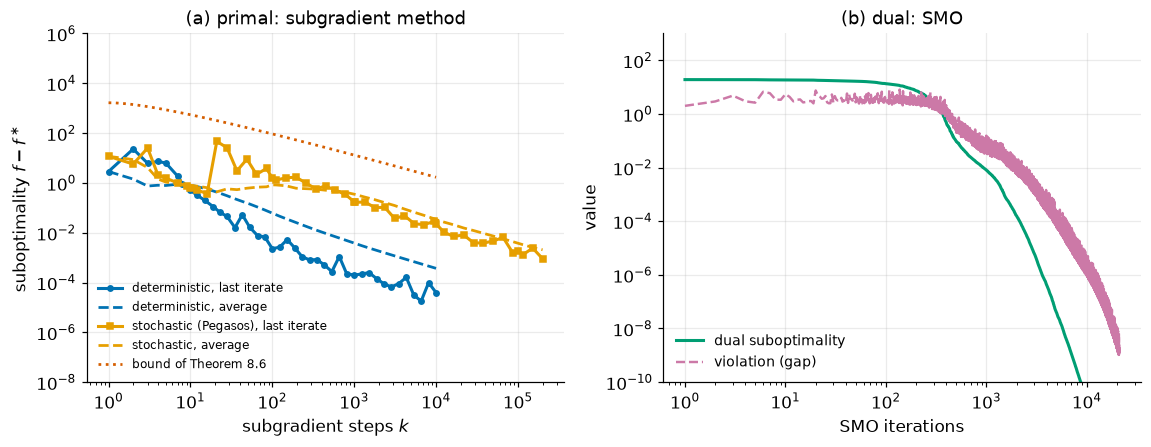

In [16]:
# Figure 8.5 — the two solvers: subgradient method (primal) and SMO (dual)
_, _, it_smo, hist_smo = smo(K_b, sb, C_b, tol=1e-9, record=True)
dual_star = hist_smo[-1, 1]


def figure_8_5():
    fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.2))
    ax = axes[0]
    ax.loglog(rec_full[:, 0], np.maximum(rec_full[:, 1], 1e-12), color=BLUE, lw=2, marker="o", ms=3.5, label="deterministic, last iterate")
    ax.loglog(rec_full[:, 0], rec_full[:, 2], color=BLUE, lw=1.8, ls="--", label="deterministic, average")
    ax.loglog(rec_sgd[:, 0], np.maximum(rec_sgd[:, 1], 1e-12), color=ORANGE, lw=2, marker="s", ms=3.5, label="stochastic (Pegasos), last iterate")
    ax.loglog(rec_sgd[:, 0], rec_sgd[:, 2], color=ORANGE, lw=1.8, ls="--", label="stochastic, average")
    kk = np.logspace(0, 4, 100)
    ax.loglog(kk, g_full**2 * (1 + np.log(kk)) / (2 * lam_b * kk), color=VERMILION, lw=1.8, ls=":", label="bound of Theorem 8.6")
    ax.set(xlabel="subgradient steps $k$", ylabel=r"suboptimality $f - f^\ast$", ylim=(1e-8, 1e6), title="(a) primal: subgradient method")
    ax.legend(frameon=False, fontsize=8, loc="lower left")
    ax = axes[1]
    ax.loglog(np.arange(1, len(hist_smo) + 1), np.maximum(dual_star - hist_smo[:, 1], 1e-14), color=GREEN, lw=2, label="dual suboptimality")
    ax.loglog(np.arange(1, len(hist_smo) + 1), hist_smo[:, 0], color=PURPLE, lw=1.6, ls="--", label="violation (gap)")
    ax.set(xlabel="SMO iterations", ylabel="value", title="(b) dual: SMO", ylim=(1e-10, 1e3))
    ax.legend(frameon=False, fontsize=9, loc="lower left")
    fig.tight_layout()
    plt.show()


figure_8_5()

### 8.5.3 What the libraries do

scikit-learn offers three implementations of the linear SVM, which solve slightly different problems.

| Estimator | Algorithm | Intercept | Kernels | Cost |
|---|---|---|---|---|
| `SVC(kernel="linear")` | libsvm: SMO with a second-order choice of the pair | **free** (outside the norm), as in this chapter | yes (Chapter 9) | between $O(n^2)$ and $O(n^3)$ time, $O(n^2)$ cache of the Gram matrix |
| `LinearSVC` | liblinear: dual coordinate descent (or a primal Newton method) | **penalized** (a constant feature, scaled by `intercept_scaling`) | no | $O(np)$ per sweep, fast for large $n$ |
| `SGDClassifier(loss="hinge")` | stochastic subgradient (Section 7.6) with a decreasing step | free | no | $O(p)$ per update, a few epochs |

The intercept is the source of small differences between the results. The cell below fits the same problem ($C = 1$, Breast Cancer) with the four variants and compares the weights with those of `SVC`.

In [17]:
ref_w, ref_b = svm_b.coef_.ravel(), svm_b.intercept_[0]
variants = {
    "SVC (libsvm), intercept free": svm_b,
    "LinearSVC, hinge, intercept_scaling = 1": LinearSVC(C=C_b, loss="hinge", dual=True, max_iter=1_000_000, tol=1e-8).fit(Zb, sb),
    "LinearSVC, hinge, intercept_scaling = 10": LinearSVC(C=C_b, loss="hinge", dual=True, intercept_scaling=10, max_iter=1_000_000, tol=1e-8).fit(Zb, sb),
    "SGDClassifier, hinge, 2000 epochs": SGDClassifier(loss="hinge", alpha=1 / (C_b * n_b), max_iter=2000, tol=None, random_state=SEED).fit(Zb, sb),
    "LinearSVC, squared hinge": LinearSVC(C=C_b, loss="squared_hinge", dual=True, max_iter=1_000_000, tol=1e-8).fit(Zb, sb),
}
rows = []
for name, m_ in variants.items():
    w_, b_ = m_.coef_.ravel(), m_.intercept_[0]
    rows.append({"variant": name, "||w||": np.linalg.norm(w_), "b": b_, "rel. distance of w from SVC": np.linalg.norm(w_ - ref_w) / np.linalg.norm(ref_w),
                 "test accuracy": np.mean(np.sign(Zb_te @ w_ + b_) == sb_te), "iterations": float(np.ravel(getattr(m_, "n_iter_", np.nan))[0])})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}" if abs(v) < 1e4 else f"{v:.0f}"))

                                 variant  ||w||       b  rel. distance of w from SVC  test accuracy  iterations
            SVC (libsvm), intercept free 2.7119 -0.0505                       0.0000         0.9580   9620.0000
 LinearSVC, hinge, intercept_scaling = 1 2.7177 -0.0422                       0.0065         0.9580   5764.0000
LinearSVC, hinge, intercept_scaling = 10 2.7119 -0.0504                       0.0001         0.9580       78421
       SGDClassifier, hinge, 2000 epochs 2.7264 -0.0454                       0.0121         0.9580   2000.0000
                LinearSVC, squared hinge 3.0407  0.2192                       0.5017         0.9650    869.0000


The four hinge-loss solutions agree to within $1.2\%$ in their weights and have the same test accuracy ($0.958$), and the differences come from details of the problem, not from the algorithm. `LinearSVC` penalizes the intercept, and its solution is $0.65\%$ away from that of `SVC`; with `intercept_scaling=10` the intercept is penalized $100$ times less and the distance falls to $0.01\%$, but liblinear then needs $72{,}493$ iterations instead of $5{,}453$: the same trade-off as in Section 7.4, where the scale of one coordinate controls the conditioning of the whole problem. `SGDClassifier` with $2000$ epochs is stochastic and is $1.2\%$ away. The last row is a *different model*: the squared hinge loss penalizes the violations quadratically, gives a larger norm ($3.04$) and a different weight vector ($50\%$ away) and, on this test set, a slightly different accuracy ($0.965$, one more patient classified correctly): neither is better, since the test set cannot decide. In practice: use `SVC` when $n$ is up to a few tens of thousands (it is the only one that handles kernels), and `LinearSVC` or `SGDClassifier` for large $n$ with a linear model.

## 8.6 Why the margin matters: generalization

### 8.6.1 The margin bound, evaluated

Theorem 3.7 said that, with probability at least $1 - \delta$, **all** linear classifiers $\mathbf{w}^\top\mathbf{x}$ with $\lVert\mathbf{w}\rVert\le B$ on data with $\lVert\mathbf{x}\rVert\le R$ satisfy

$$
\mathbb{P}\big(y\,\mathbf{w}^\top\mathbf{x}\le 0\big)\ \le\ \frac1n\#\{i : y_i\mathbf{w}^\top\mathbf{x}_i < \gamma\} + \frac{2BR}{\gamma\sqrt n} + \sqrt{\frac{\ln(1/\delta)}{2n}} .
$$

The SVM is built to make this expression small: the constraints $y_i f(\mathbf{x}_i)\ge 1$ make the first term small ($\gamma = 1$), and minimizing $\lVert\mathbf{w}\rVert$ makes $B$ small; the parameter $C$ trades the two. To apply the theorem with an intercept we use the augmented vectors $\tilde{\mathbf{x}} = (1, \mathbf{x})$ and $\tilde{\mathbf{w}} = (b, \mathbf{w})$, so that $B = \lVert\tilde{\mathbf{w}}\rVert$ and $R = \max_i\lVert\tilde{\mathbf{x}}_i\rVert$. Strictly, $B$ must be fixed before seeing the data; using the value found by the algorithm costs a union bound over a grid of values of $B$, which adds a small term that we ignore. The cell evaluates the bound on the Breast Cancer training set for several values of $C$. As in Section 3.8.3, we also compute the variant in which the worst-case radius $R$ is replaced by the root-mean-square norm of the sample, $R_{\text{rms}}$: this is **not** what Theorem 3.7 states (the outlier radius is what the proof needs), but it is the data-dependent form that Section 3.8.3 found to be much tighter, and it is useful as a heuristic.

In [18]:
Zb_aug = np.c_[np.ones(n_b), Zb]                                           # augmented vectors (1, x)
R_max = np.linalg.norm(Zb_aug, axis=1).max()
R_rms = np.sqrt(np.mean(np.sum(Zb_aug**2, axis=1)))
conf_term = np.sqrt(np.log(1 / 0.05) / (2 * n_b))                          # delta = 0.05
print(f"R (largest norm) = {R_max:.2f}, R_rms = {R_rms:.2f}, confidence term = {conf_term:.3f}")
rows = []
for C in [0.01, 0.03, 0.1, 1, 1000]:
    m_ = SVC(kernel="linear", C=C, tol=1e-9).fit(Zb, sb)
    w_, b_ = m_.coef_.ravel(), m_.intercept_[0]
    B = np.sqrt(w_ @ w_ + b_**2)
    frac = np.mean(sb * (Zb @ w_ + b_) < 1 - 1e-6)                         # fraction of training points with margin below gamma = 1
    cap_max, cap_rms = 2 * B * R_max / np.sqrt(n_b), 2 * B * R_rms / np.sqrt(n_b)
    rows.append({"C": C, "B": B, "below margin": frac, "capacity (R)": cap_max, "capacity (R_rms)": cap_rms,
                 "bound (R)": frac + cap_max + conf_term, "bound (R_rms)": frac + cap_rms + conf_term,
                 "test error": np.mean(np.sign(Zb_te @ w_ + b_) != sb_te)})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

R (largest norm) = 19.58, R_rms = 5.57, confidence term = 0.059
       C      B  below margin  capacity (R)  capacity (R_rms)  bound (R)  bound (R_rms)  test error
   0.010  0.767         0.218         1.455             0.414      1.733          0.691       0.042
   0.030  1.034         0.146         1.961             0.558      2.166          0.762       0.021
   0.100  1.419         0.092         2.692             0.766      2.843          0.916       0.021
   1.000  2.712         0.040         5.146             1.463      5.245          1.563       0.042
1000.000 28.408         0.035        53.898            15.327     53.992         15.421       0.070


With the radius $R$ of the theorem the bound is above $1.7$ for every value of $C$ and says nothing: the true error is between $2\%$ and $7\%$. The radius is dominated by an outlier patient ($R = 19.6$, while the root-mean-square norm is $5.6$), and the capacity term $2BR/\sqrt n$ is between $1.5$ and $54$ when it should be well below $1$ to mean anything. With the heuristic $R_{\text{rms}}$ the bound falls below $1$ for $C\le 0.1$ ($0.69$, $0.76$, $0.92$), is vacuous again at $C = 1$ ($1.56$) and absurd for the hard margin ($15.4$). The numbers are not predictions, but the **shape** of the bound in $C$ is informative. The first term, the fraction of training patients below the margin, falls as $C$ grows, from $22\%$ to $3.5\%$; the capacity term grows in proportion to $B = \lVert(\mathbf{w}, b)\rVert$, from $0.77$ to $28.4$ (a factor $37$); and the sum is smallest, among the values tried, at the smallest $C$ ($0.01$). The test error is lowest ($2.1\%$) at $C = 0.03$ and $0.1$, a factor of three to ten above the value that minimizes the bound, and **highest for the hard margin** ($7.0\%$, ten errors among $143$ patients): the hard-margin classifier has no training point below the margin, but its capacity term is the largest of the table. *A large margin is not enough; what the theorem controls is the norm of $\mathbf{w}$ relative to the radius of the data, and the soft margin gives up some training points to pay for a smaller norm.*

### 8.6.2 A different kind of guarantee: leave-one-out and the support vectors

The margin bound is a statement about *all* classifiers of a class. The sparsity of the SVM gives a very different guarantee, specific to the classifier that the algorithm returns.

:::{admonition} Proposition 8.8 (leave-one-out error and support vectors)
:class: tip
Let $\hat\alpha$, $\hat b$ be a solution of the soft-margin SVM on $n$ training examples, with $N_{\text{SV}} = \#\{i : \hat\alpha_i > 0\}$ support vectors. Then the leave-one-out error satisfies

$$
\widehat{\mathrm{err}}_{\mathrm{LOO}} = \frac1n\sum_{i=1}^n\mathbb{I}\big[\,y_i\ne\hat f^{(-i)}(\mathbf{x}_i)\big]\ \le\ \frac{N_{\text{SV}}}{n},
$$

where $\hat f^{(-i)}$ is the SVM trained on the other $n - 1$ examples (the solution being unique, or any consistent choice among the solutions when it is not).
:::

:::{admonition} Proof
:class: dropdown
Take an example $k$ with $\hat\alpha_k = 0$. Remove it, and keep the other multipliers and the same $\hat b$. The vector $\hat{\mathbf{w}} = \sum_{i\ne k}\hat\alpha_iy_i\mathbf{x}_i$ is unchanged because the removed term was zero, the constraints $0\le\alpha_i\le C$ and $\sum_i\alpha_iy_i = 0$ still hold, and the KKT conditions of Theorem 8.4 for the examples $i\ne k$ involve only the scores $\hat{\mathbf{w}}^\top\mathbf{x}_i + \hat b$, which have not changed. Since these conditions are sufficient for optimality, $(\hat\alpha_{-k}, \hat b)$ is a solution of the SVM trained *without* example $k$, so $\hat f^{(-k)} = \hat f$ on the examples. Now $\hat\alpha_k = 0$ implies $y_k\hat f(\mathbf{x}_k)\ge 1 > 0$ (Theorem 8.4): the example is classified correctly by $\hat f$, hence by $\hat f^{(-k)}$. Therefore only support vectors can be leave-one-out errors, and there are $N_{\text{SV}}$ of them at most. $\square$
:::

This is a bound that can be *computed from the training run*, without refitting: like Proposition 6.8 (the leave-one-out shortcut for ridge) it avoids the $n$ refits, but it does so through the sparsity of the solution instead of an algebraic identity, and it bounds the error instead of computing it. It is also a statement about the number of support vectors as a measure of the complexity of the solution: the *smaller the fraction of support vectors, the better the guarantee*, which is a different thing from the number of parameters of the model (which is $d + 1 = 31$ here, whatever $C$). We check it on Breast Cancer, for a grid of values of $C$, with the explicit leave-one-out refits (426 per value of $C$) and the 10-fold cross-validation of Chapter 5, and we record the training and test errors. *To keep the code short the features are standardized once on the training set, which leaks a negligible amount of information into the validation folds for this comparison; Section 2.7 explains the proper way, a pipeline, which Chapter 5 applies and Section 8.7 uses.*

In [19]:
C_grid = np.array([0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100])
skf10 = StratifiedKFold(10, shuffle=True, random_state=SEED)
rows = []
for C in C_grid:
    m_ = SVC(kernel="linear", C=C, tol=1e-6).fit(Zb, sb)
    loo_pred = cross_val_predict(SVC(kernel="linear", C=C, tol=1e-6), Zb, sb, cv=LeaveOneOut())
    cv_pred = cross_val_predict(SVC(kernel="linear", C=C, tol=1e-6), Zb, sb, cv=skf10)
    rows.append({"C": C, "support vectors": len(m_.support_), "SV fraction (LOO bound)": len(m_.support_) / n_b,
                 "LOO error": np.mean(loo_pred != sb), "10-fold error": np.mean(cv_pred != sb),
                 "training error": 1 - m_.score(Zb, sb), "test error": 1 - m_.score(Zb_te, sb_te)})
svm_path = pd.DataFrame(rows)
print(svm_path.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("LOO error <= SV fraction for every C:", bool((svm_path["LOO error"] <= svm_path["SV fraction (LOO bound)"] + 1e-12).all()))

       C  support vectors  SV fraction (LOO bound)  LOO error  10-fold error  training error  test error
  0.0010              213                   0.5000     0.0587         0.0610          0.0587      0.0699
  0.0030              148                   0.3474     0.0516         0.0516          0.0493      0.0490
  0.0100              101                   0.2371     0.0352         0.0352          0.0329      0.0420
  0.0300               74                   0.1737     0.0258         0.0282          0.0188      0.0210
  0.1000               51                   0.1197     0.0258         0.0305          0.0164      0.0210
  0.3000               42                   0.0986     0.0352         0.0305          0.0094      0.0350
  1.0000               36                   0.0845     0.0376         0.0305          0.0094      0.0420
  3.0000               30                   0.0704     0.0352         0.0305          0.0070      0.0420
 10.0000               28                   0.0657     

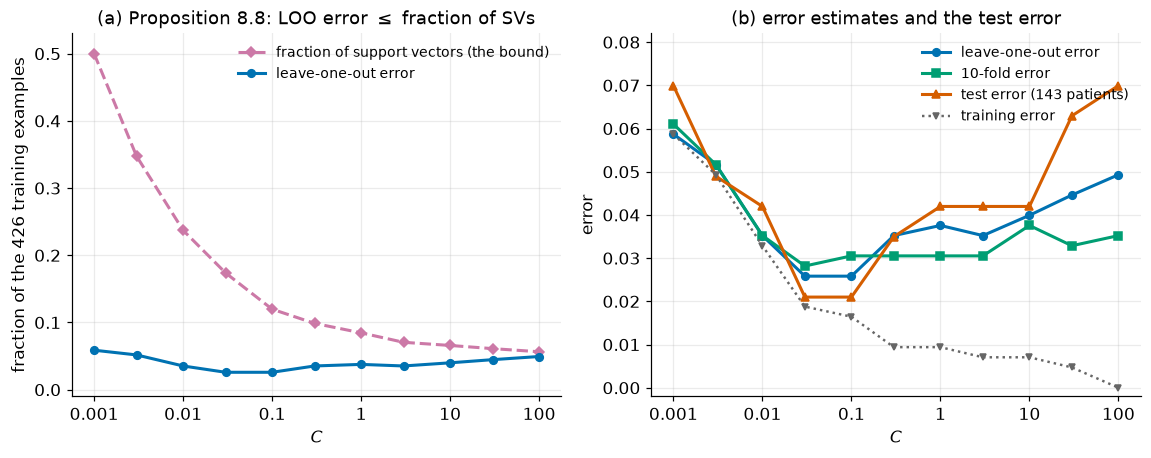

In [20]:
# Figure 8.6 — the path in C: support vectors, leave-one-out, cross-validation and test error
def figure_8_6():
    p = svm_path
    fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.3))
    ax = axes[0]
    ax.plot(p["C"], p["SV fraction (LOO bound)"], color=PURPLE, lw=2, marker="D", ms=5, ls="--", label="fraction of support vectors (the bound)")
    ax.plot(p["C"], p["LOO error"], color=BLUE, lw=2, marker="o", ms=5, label="leave-one-out error")
    ax.set(xlabel="$C$", ylabel="fraction of the 426 training examples", ylim=(-0.01, 0.53), title="(a) Proposition 8.8: LOO error $\\leq$ fraction of SVs")
    ax.legend(frameon=False, fontsize=9, loc="upper right")
    ax = axes[1]
    ax.plot(p["C"], p["LOO error"], color=BLUE, lw=2, marker="o", ms=5, label="leave-one-out error")
    ax.plot(p["C"], p["10-fold error"], color=GREEN, lw=2, marker="s", ms=5, label="10-fold error")
    ax.plot(p["C"], p["test error"], color=VERMILION, lw=2, marker="^", ms=5, label="test error (143 patients)")
    ax.plot(p["C"], p["training error"], color="0.4", lw=1.6, marker="v", ms=4, ls=":", label="training error")
    ax.set(xlabel="$C$", ylabel="error", ylim=(-0.002, 0.082), title="(b) error estimates and the test error")
    ax.legend(frameon=False, fontsize=9, loc="upper right")
    for ax in axes:
        ax.set_xscale("log")
        ax.set_xticks(C_grid[::2])
        ax.set_xticklabels([f"{c:g}" for c in C_grid[::2]])
        ax.minorticks_off()
    fig.tight_layout()
    plt.show()


figure_8_6()

In [21]:
cv_err = svm_path["10-fold error"].to_numpy()
i_cv = int(np.argmin(cv_err))
se = np.sqrt(cv_err[i_cv] * (1 - cv_err[i_cv]) / n_b)                      # binomial standard error of the best CV error
i_1se = int(np.flatnonzero(cv_err <= cv_err[i_cv] + se)[0])               # most regularized model within one standard error
for name, i in [("minimum of the 10-fold error", i_cv), ("one-standard-error rule", i_1se)]:
    r = svm_path.iloc[i]
    print(f"{name}: C = {r['C']:g} (10-fold error {r['10-fold error']:.4f}, {int(r['support vectors'])} support vectors), "
          f"test error {r['test error']:.4f} = {round(r['test error'] * len(sb_te))} errors out of {len(sb_te)}")
print(f"standard error of the best 10-fold error: {se:.4f}; the 10-fold error stays within one standard error for C between "
      f"{svm_path['C'][cv_err <= cv_err[i_cv] + se].min():g} and {svm_path['C'][cv_err <= cv_err[i_cv] + se].max():g}")

minimum of the 10-fold error: C = 0.03 (10-fold error 0.0282, 74 support vectors), test error 0.0210 = 3 errors out of 143
one-standard-error rule: C = 0.01 (10-fold error 0.0352, 101 support vectors), test error 0.0420 = 6 errors out of 143
standard error of the best 10-fold error: 0.0080; the 10-fold error stays within one standard error for C between 0.01 and 100


Figure 8.6(a) confirms Proposition 8.8: the leave-one-out error is below the fraction of support vectors for every $C$. The bound is loose when $C$ is small (at $C = 0.003$ the fraction is $35\%$ and the leave-one-out error $5.2\%$) and tight when $C$ is large (at $C = 100$: $5.6\%$ against $4.9\%$, with $24$ support vectors). At the values of $C$ where the classification is best ($0.03$ to $0.1$) the fraction of support vectors is $12\%$ to $17\%$, four to six times the leave-one-out error, so the bound is informative about the *trend* (the sparser the solution, the smaller the guarantee) more than about the level. Panel (b) shows the three error estimates of the chapter on one plot. The leave-one-out, the $10$-fold and the test error fall from about $6\%$ at $C = 0.001$ to a minimum of $2.6\%$ to $2.8\%$ (leave-one-out and $10$-fold) and $2.1\%$ (test) at $C = 0.03$ to $0.1$, and rise slowly for larger $C$ (to $5\%$ for the leave-one-out and $7\%$ for the test error) while the training error falls to zero: the U-shape of Chapters 4 to 6, with a mild right branch.

The selection of $C$ shows the limits of the protocol. The minimum of the $10$-fold error is at $C = 0.03$ ($2.8\%$, standard error $0.8\%$) and gives $3$ errors on the test set; the one-standard-error rule of Section 5.4.1 chooses $C = 0.01$ and gives $6$. But the $10$-fold error stays within one standard error of its minimum for **every** $C$ between $0.01$ and $100$, four orders of magnitude, so the data cannot tell these values apart, and the difference between $3$ and $6$ test errors is of the size of the noise (the standard error of an error rate of $3\%$ on $143$ patients is $1.4\%$). The practical consequence is the one of Section 5.4.2: a coarse logarithmic grid for $C$ is enough, and one should not read much into the position of the minimum.

## 8.7 Using SVMs in practice

### 8.7.1 Scale the features

The margin is a Euclidean distance, so *a feature with a large scale dominates it*, exactly as for $k$-nearest neighbors (Section 4.8.2) and ridge (Section 6.3.1): the SVM is **not** invariant to the scaling of the features. The SVM is also an optimization problem whose conditioning depends on the scales (Section 7.4). The cell compares the same linear SVM, with $C = 1$, on the raw Breast Cancer features and on the standardized ones (the standardization inside a pipeline, fitted on the training set only), by the number of solver iterations, the test accuracy and the AUC.

In [22]:
rows = []
for name, est in [("raw features", make_pipeline(SVC(kernel="linear", C=1.0, tol=1e-4, cache_size=500))),
                  ("standardized", make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0, tol=1e-4, cache_size=500)))]:
    t0 = time.perf_counter()
    est.fit(Xb_tr, sb)
    elapsed = time.perf_counter() - t0
    svc_ = est[-1]
    score_te = est.decision_function(Xb_te)
    rows.append({"features": name, "solver iterations": int(np.ravel(svc_.n_iter_)[0]), "support vectors": len(svc_.support_),
                 "test accuracy": np.mean(np.sign(score_te) == sb_te), "test AUC": roc_auc_score(sb_te, score_te)})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

    features  solver iterations  support vectors  test accuracy  test AUC
raw features          159687807               43         0.9371    0.9937
standardized               2973               36         0.9580    0.9929


Without standardization the solver of libsvm needs about $1.6\cdot 10^8$ iterations at $C = 1$, against about $3.0\cdot 10^3$ with standardization, more than four orders of magnitude fewer. The standard deviations of the raw features range from $0.003$ (the error of the fractal dimension) to $569$ (the worst area), the Gram matrix is dominated by the features of large scale, and the dual problem is badly conditioned, the cause that Section 7.4 identified for gradient descent. The classifier changes too: $43$ support vectors against $36$ and a test accuracy of $0.937$ against $0.958$ ($9$ errors against $6$). The AUC is not lower for the raw features ($0.994$ against $0.993$), which suggests that what changes is mainly the position of the boundary and not the ordering of the patients; with $143$ test patients we do not read more than that into it. The rule is the one of Chapters 2 and 4: **standardize inside the pipeline**, always, before an SVM.

### 8.7.2 SVM and logistic regression, compared with the protocols of Chapter 5

How does the SVM compare with the regularized logistic regression of Chapter 6? We tune $C$ for both by the 10-fold cross-validation error on the same folds (the same standardized training set as above), evaluate on the test set once, and compare the two sets of predictions with McNemar's exact test (Section 5.5.1).

In [23]:
rows, preds = [], {}
for name, make in [("SVM (linear)", lambda C: SVC(kernel="linear", C=C, tol=1e-6)),
                   ("logistic regression", lambda C: LogisticRegression(C=C, max_iter=10_000))]:
    errs = [np.mean(cross_val_predict(make(C), Zb, sb, cv=skf10) != sb) for C in C_grid]
    C_best = C_grid[int(np.argmin(errs))]
    fit_ = make(C_best).fit(Zb, sb)
    score_ = fit_.decision_function(Zb_te)
    preds[name] = np.sign(score_)
    rows.append({"model": name, "C chosen by 10-fold CV": C_best, "10-fold error": min(errs), "test accuracy": np.mean(preds[name] == sb_te),
                 "test errors": int(np.sum(preds[name] != sb_te)), "test AUC": roc_auc_score(sb_te, score_)})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
a_, b_ = preds["SVM (linear)"], preds["logistic regression"]
n_sv_only, n_lr_only = int(np.sum((a_ == sb_te) & (b_ != sb_te))), int(np.sum((a_ != sb_te) & (b_ == sb_te)))
p_mc = binomtest(min(n_sv_only, n_lr_only), n_sv_only + n_lr_only, 0.5).pvalue if n_sv_only + n_lr_only > 0 else 1.0
print(f"patients classified correctly by the SVM only: {n_sv_only}; by the logistic regression only: {n_lr_only}; McNemar exact p-value = {p_mc:.3f}")

              model  C chosen by 10-fold CV  10-fold error  test accuracy  test errors  test AUC
       SVM (linear)                  0.0300         0.0282         0.9790            3    0.9977
logistic regression                  1.0000         0.0211         0.9650            5    0.9962
patients classified correctly by the SVM only: 2; by the logistic regression only: 0; McNemar exact p-value = 0.500


Tuned on the same folds, the SVM chooses $C = 0.03$ ($10$-fold error $2.8\%$) and the logistic regression $C = 1$ ($2.1\%$): the logistic regression is ahead in cross-validation and the SVM on the test set ($3$ errors against $5$; AUC $0.998$ against $0.996$). Neither lead means anything. On the $143$ test patients the SVM is right and the logistic regression wrong for $2$ patients, and the opposite happens for none (McNemar's exact $p = 0.50$); the cross-validation difference of $0.7$ points is smaller than the standard error of each estimate ($0.8$ points). Both models are linear classifiers with an $\ell_2$ penalty that differ only by the loss (Section 8.4), and on these data there is no evidence in favor of either. The choice is made on other grounds: probabilities and a smooth path in $C$ for the logistic regression; sparsity in the examples, the leave-one-out bound and kernels (Chapter 9) for the SVM.

### 8.7.3 From scores to probabilities: Platt scaling

The score $f(\mathbf{x})$ of an SVM is not a probability (Proposition 8.5), but a monotone transformation of it can be one. **Platt scaling** (Platt, 1999) fits the two-parameter model $\mathbb{P}(y = 1\mid f) = \sigma(Af + B)$ by maximum likelihood, which is a logistic regression on the one-dimensional score, using held-out scores so that the fit is not distorted by the training examples (whose scores are pushed beyond the margin). It does not change the ranking of the examples: the AUC is unchanged. This is the recalibration of Section 5.6.4, and `CalibratedClassifierCV(method="sigmoid")` does it with cross-validation. The cell compares, for two values of $C$, the log-loss and Brier score of three probability estimates on the test set: the raw sigmoid $\sigma(f)$ (which has no justification), the Platt-scaled SVM, and the logistic regression with the same $C$.

In [24]:
rows, slopes = [], {}
for C in [0.03, 1.0]:
    svc_ = SVC(kernel="linear", C=C, tol=1e-6).fit(Zb, sb)
    d_te = svc_.decision_function(Zb_te)
    p_raw = 1 / (1 + np.exp(-d_te))
    platt = CalibratedClassifierCV(SVC(kernel="linear", C=C, tol=1e-6), method="sigmoid", cv=5).fit(Zb, yb_tr)
    p_platt = platt.predict_proba(Zb_te)[:, 1]
    slopes[C] = np.mean([-cc.calibrators[0].a_ for cc in platt.calibrated_classifiers_])      # the slope A of sigma(A f + B), averaged over the 5 folds
    lr_ = LogisticRegression(C=C, max_iter=10_000).fit(Zb, yb_tr)
    p_lr = lr_.predict_proba(Zb_te)[:, 1]
    for name, p in [("raw sigmoid of the score", p_raw), ("Platt scaling", p_platt), ("logistic regression", p_lr)]:
        rows.append({"C": C, "probability estimate": name, "log-loss": log_loss(yb_te, p), "Brier score": brier_score_loss(yb_te, p),
                     "AUC": roc_auc_score(yb_te, d_te if name != "logistic regression" else lr_.decision_function(Zb_te))})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("average slope A of the Platt sigmoid:", {C: round(float(a), 2) for C, a in slopes.items()})

     C     probability estimate  log-loss  Brier score    AUC
0.0300 raw sigmoid of the score    0.1667       0.0377 0.9977
0.0300            Platt scaling    0.1026       0.0247 0.9977
0.0300      logistic regression    0.1212       0.0289 0.9985
1.0000 raw sigmoid of the score    0.1201       0.0324 0.9929
1.0000            Platt scaling    0.1304       0.0350 0.9929
1.0000      logistic regression    0.0776       0.0224 0.9962
average slope A of the Platt sigmoid: {0.03: 1.74, 1.0: 0.86}


For $C = 0.03$ (the value chosen by cross-validation) the raw sigmoid of the score has a log-loss of $0.167$ and a Brier score of $0.0377$; Platt scaling lowers them to $0.103$ and $0.0247$, better than the logistic regression with the same $C$ ($0.121$ and $0.0289$). The slope of the fitted sigmoid is $A\approx 1.7$: with this $C$ the scores are on too small a scale and the raw sigmoid is under-confident, and the calibration stretches them. For $C = 1$ the scores are on a larger scale, the slope is $A\approx 0.9$, and the raw sigmoid is already nearly right: Platt scaling does *not* help (log-loss $0.130$ against $0.120$, Brier $0.0350$ against $0.0324$), and the logistic regression is clearly better ($0.078$ and $0.0224$, the value of Section 6.8). The AUC is the same for the raw and the Platt-scaled score, since the transformation is monotone. The lesson is that **the calibration of a raw SVM score depends on $C$**, through the scale of $\mathbf{w}$, and that when probabilities are needed one should either calibrate on held-out scores or use a model whose loss is a likelihood. With $143$ test patients, differences of $0.01$ in log-loss are within the noise: a handful of confident errors dominate this metric (Section 5.6.4).

### 8.7.4 More than two classes

The SVM is a binary classifier, and two reductions extend it to $K$ classes. **One-vs-rest** (OvR) trains $K$ classifiers, each separating one class from all the others, and predicts the class with the largest score. **One-vs-one** (OvO) trains $K(K - 1)/2$ classifiers, each on the examples of two classes only, and predicts by majority vote. For Digits ($K = 10$) these are $10$ and $45$ problems; the OvO problems are smaller (each uses about $2/K$ of the data). `SVC` always uses one-vs-one internally (its option `decision_function_shape` only reshapes the output), and `LinearSVC` uses one-vs-rest. We compare, with $C$ tuned by 5-fold cross-validation on the training set (the split of Chapters 6 and 7: 1347 training and 450 test images), both reductions with the softmax regression of Section 6.6.

In [25]:
dg = load_digits()
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(dg.data, dg.target, test_size=0.25, random_state=SEED, stratify=dg.target)
skf5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
candidates = {
    "SVM one-vs-one (45 problems)": (make_pipeline(StandardScaler(), SVC(kernel="linear", tol=1e-4)), {"svc__C": np.logspace(-4, 2, 7)}),
    "SVM one-vs-rest (10 problems)": (make_pipeline(StandardScaler(), OneVsRestClassifier(SVC(kernel="linear", tol=1e-4))),
                                      {"onevsrestclassifier__estimator__C": np.logspace(-4, 2, 7)}),
    "softmax regression (1 problem)": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=20_000)), {"logisticregression__C": np.logspace(-3, 2, 6)}),
}
rows, preds_g = [], {}
for name, (est, grid_) in candidates.items():
    search = GridSearchCV(est, grid_, cv=skf5, scoring="accuracy").fit(Xg_tr, yg_tr)
    preds_g[name] = search.predict(Xg_te)
    rows.append({"method": name, "C chosen": list(search.best_params_.values())[0], "5-fold accuracy": search.best_score_,
                 "test accuracy": np.mean(preds_g[name] == yg_te), "test errors": int(np.sum(preds_g[name] != yg_te))})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
names_g = list(preds_g)
for i in range(len(names_g)):
    for j in range(i + 1, len(names_g)):
        a_, b_ = preds_g[names_g[i]] == yg_te, preds_g[names_g[j]] == yg_te
        only_a, only_b = int(np.sum(a_ & ~b_)), int(np.sum(~a_ & b_))
        p_ = binomtest(min(only_a, only_b), only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
        print(f"McNemar, {names_g[i]} vs {names_g[j]}: {only_a} vs {only_b} discordant, p = {p_:.3f}")

                        method  C chosen  5-fold accuracy  test accuracy  test errors
  SVM one-vs-one (45 problems)    1.0000           0.9799         0.9800            9
 SVM one-vs-rest (10 problems)    0.1000           0.9555         0.9556           20
softmax regression (1 problem)   10.0000           0.9673         0.9644           16
McNemar, SVM one-vs-one (45 problems) vs SVM one-vs-rest (10 problems): 15 vs 4 discordant, p = 0.019
McNemar, SVM one-vs-one (45 problems) vs softmax regression (1 problem): 10 vs 3 discordant, p = 0.092
McNemar, SVM one-vs-rest (10 problems) vs softmax regression (1 problem): 6 vs 10 discordant, p = 0.454


One-vs-one is the best of the three on this problem: $9$ errors among $450$ test images ($0.980$), against $20$ ($0.956$) for one-vs-rest and $16$ ($0.964$) for the softmax regression tuned in the same way (Section 6.6 reported $0.973$, with $C$ chosen by the log-loss: $12$ errors; the choice of the criterion alone moves the result by a few images). McNemar's test separates one-vs-one from one-vs-rest ($15$ against $4$ discordant images, $p = 0.019$; with a Bonferroni correction for three comparisons, $0.057$), and does not separate it from the softmax regression ($10$ against $3$, $p = 0.092$) nor one-vs-rest from the softmax regression ($p = 0.45$). So the evidence favors one-vs-one over one-vs-rest, and is only suggestive against the softmax regression. A plausible reason for the first difference, which we have not tested, is that each pairwise problem (two digits) is much easier, and closer to linearly separable, than one digit against nine heterogeneous others; the price is $45$ problems instead of $10$, each on about a fifth of the data.

## 8.8 Beyond the linear SVM

### 8.8.1 The dual only needs inner products: a preview of kernels

Look again at the dual problem of Theorem 8.4 and at the classifier: the training data enter only through the inner products $\mathbf{x}_i^\top\mathbf{x}_j$ (the Gram matrix of the SMO of Section 8.5.2), and a new point enters only through $\mathbf{x}_i^\top\mathbf{x}$:

$$
\hat f(\mathbf{x}) = \sum_{i=1}^n\hat\alpha_iy_i\,\mathbf{x}_i^\top\mathbf{x} + \hat b .
$$

Suppose that we first map the data with a function $\boldsymbol\phi:\mathbb{R}^d\to\mathbb{R}^p$ into a space of **features** where a linear classifier is more powerful, as in Section 6.7, and train the SVM on $\boldsymbol\phi(\mathbf{x}_i)$. Then only the inner products $k(\mathbf{x}, \mathbf{z}) = \boldsymbol\phi(\mathbf{x})^\top\boldsymbol\phi(\mathbf{z})$ are needed, and **we never have to compute $\boldsymbol\phi$** if we can evaluate $k$ directly. For two features and the map $\boldsymbol\phi(\mathbf{x}) = (x_1^2,\ x_2^2,\ \sqrt2x_1x_2,\ \sqrt2x_1,\ \sqrt2x_2,\ 1)$, a direct computation gives

$$
\boldsymbol\phi(\mathbf{x})^\top\boldsymbol\phi(\mathbf{z}) = x_1^2z_1^2 + x_2^2z_2^2 + 2x_1x_2z_1z_2 + 2x_1z_1 + 2x_2z_2 + 1 = (\mathbf{x}^\top\mathbf{z} + 1)^2 ,
$$

the **polynomial kernel** of degree $2$: its cost is that of an inner product in $\mathbb{R}^2$, not in $\mathbb{R}^6$, and for $d = 30$ features and degree $5$ the space of features has dimension $\binom{35}{5} = 324{,}632$ while the kernel is still $O(d)$. Chapter 9 develops the theory (which functions $k$ are legitimate, the Gaussian kernel whose feature space is infinite-dimensional, the representer theorem). Here we only verify the identity on real data, and see what it buys. The features are the mean radius and mean texture of the Breast Cancer patients (standardized), the two features of Section 6.7. The first cell trains an SVM with the kernel `poly` ($\gamma = 1$, coefficient $1$, degree $2$) and a *linear* SVM on the six explicit features, and compares their decision functions.

In [26]:
two = ["mean radius", "mean texture"]
Xk = bc.data[two].to_numpy()
Xk_tr, Xk_te, _, _ = train_test_split(Xk, yb, test_size=0.25, random_state=SEED, stratify=yb)     # the same patients as before
scaler_k = StandardScaler().fit(Xk_tr)
Zk, Zk_te = scaler_k.transform(Xk_tr), scaler_k.transform(Xk_te)


def phi2(X):
    x1, x2, r = X[:, 0], X[:, 1], np.sqrt(2)
    return np.c_[x1**2, x2**2, r * x1 * x2, r * x1, r * x2, np.ones(len(X))]


with_kernel = SVC(kernel="poly", degree=2, gamma=1, coef0=1, C=1, tol=1e-10).fit(Zk, sb)
with_features = SVC(kernel="linear", C=1, tol=1e-10).fit(phi2(Zk), sb)
d_kernel, d_features = with_kernel.decision_function(Zk_te), with_features.decision_function(phi2(Zk_te))
print(f"kernel (x.z + 1)^2 against a linear SVM on 6 explicit features: same support vectors: {set(with_kernel.support_) == set(with_features.support_)} "
      f"({len(with_kernel.support_)}); largest difference between the test decision functions: {np.abs(d_kernel - d_features).max():.1e}")
w_feat = with_kernel.dual_coef_.ravel() @ phi2(Zk)[with_kernel.support_]                         # w in the feature space, from the dual
print("weights of the six features, from the dual:", w_feat.round(3), "(the constant feature gets weight sum alpha_i y_i = 0)")

rows = []
for degree in [1, 2, 3, 5]:
    m_ = SVC(kernel="poly", degree=degree, gamma=1, coef0=1, C=1, tol=1e-8).fit(Zk, sb)
    rows.append({"degree": degree, "support vectors": len(m_.support_), "training accuracy": m_.score(Zk, sb), "test accuracy": m_.score(Zk_te, sb_te)})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

kernel (x.z + 1)^2 against a linear SVM on 6 explicit features: same support vectors: True (106); largest difference between the test decision functions: 1.1e-10
weights of the six features, from the dual: [ 0.955 -0.28   0.467  1.655  0.55   0.   ] (the constant feature gets weight sum alpha_i y_i = 0)
 degree  support vectors  training accuracy  test accuracy
      1              119             0.8897         0.8811
      2              106             0.8991         0.8881
      3              101             0.9014         0.9091
      5              101             0.9108         0.9091


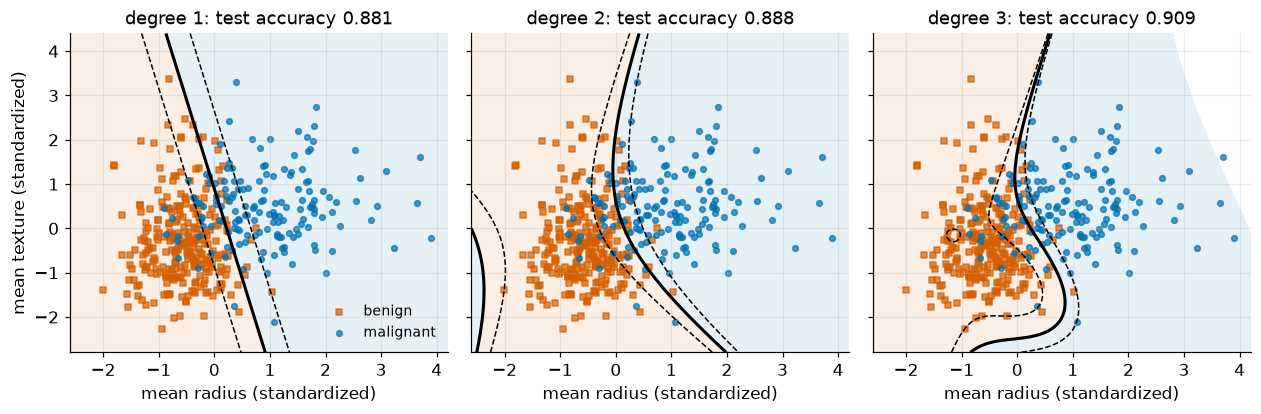

In [27]:
# Figure 8.7 — the same SVM with polynomial kernels of degree 1, 2 and 3 (two Breast Cancer features)
def figure_8_7():
    gx, gy = np.meshgrid(np.linspace(-2.6, 4.2, 220), np.linspace(-2.8, 4.4, 220))
    grid_pts = np.c_[gx.ravel(), gy.ravel()]
    fig, axes = plt.subplots(1, 3, figsize=(11.6, 3.9), sharex=True, sharey=True)
    for ax, degree in zip(axes, [1, 2, 3]):
        m_ = SVC(kernel="poly", degree=degree, gamma=1, coef0=1, C=1, tol=1e-8).fit(Zk, sb)
        d_ = m_.decision_function(grid_pts).reshape(gx.shape)
        ax.contourf(gx, gy, d_, levels=[-100, 0, 100], colors=[VERMILION, BLUE], alpha=0.10)
        ax.contour(gx, gy, d_, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[1.0, 2.0, 1.0])
        ax.scatter(*Zk[sb == -1].T, s=14, color=VERMILION, marker="s", alpha=0.7, label="benign")
        ax.scatter(*Zk[sb == 1].T, s=14, color=BLUE, marker="o", alpha=0.7, label="malignant")
        ax.set(xlim=(-2.6, 4.2), ylim=(-2.8, 4.4), xlabel="mean radius (standardized)",
               title=f"degree {degree}: test accuracy {m_.score(Zk_te, sb_te):.3f}")
    axes[0].set_ylabel("mean texture (standardized)")
    axes[0].legend(frameon=False, loc="lower right", fontsize=9)
    fig.tight_layout()
    plt.show()


figure_8_7()

The SVM with the kernel $(\mathbf{x}^\top\mathbf{z} + 1)^2$ and the linear SVM on the six explicit features have the same $106$ support vectors, and their decision functions differ by $10^{-10}$ on the test set: the kernel computes exactly the inner products of the feature space without ever forming it. The weights of the six features, recovered from the dual, show that the constant feature has weight $0$ ($=\sum_i\alpha_iy_i$, zero by the dual constraint), so the intercept is not counted twice. Higher degrees give more flexible boundaries (Figure 8.7: curved, and with wiggles near the edges of the plot, where there are no data and the polynomial extrapolates freely), but on these two features the gain in accuracy is small: the test accuracy goes from $0.881$ for the linear classifier to $0.888$, $0.909$ and $0.909$ for degrees $2$, $3$ and $5$, that is, from $17$ to $13$ errors among $143$ patients, a difference that the test set cannot confirm. Section 6.7 found the same for the polynomial logistic regression on these two features: a modest gain and a risk of overfitting. The conclusion is not that kernels are useless but that two features contain limited information; Chapter 9 will use richer kernels.

### 8.8.2 Support vector regression

The same ideas apply to regression. Replace the squared loss of Chapter 6 by the **$\varepsilon$-insensitive loss** $\ell_\varepsilon(r) = \max\{0,\ \lvert r\rvert - \varepsilon\}$ of the residual $r = y - f(\mathbf{x})$: a residual smaller than $\varepsilon$ costs nothing. **Support vector regression** (SVR) minimizes

$$
\tfrac12\lVert\mathbf{w}\rVert^2 + C\sum_{i=1}^n\max\big\{0,\ \lvert y_i - \mathbf{w}^\top\mathbf{x}_i - b\rvert - \varepsilon\big\},
$$

with the same $C$ and the same regularization as the classifier. The derivation of the dual repeats the proof of Theorem 8.4, with *two* multipliers per example, $\alpha_i$ for the constraint $y_i - f(\mathbf{x}_i)\le\varepsilon + \xi_i$ and $\alpha_i^\ast$ for $f(\mathbf{x}_i) - y_i\le\varepsilon + \xi_i^\ast$: one finds $\mathbf{w} = \sum_i(\alpha_i - \alpha_i^\ast)\mathbf{x}_i$, $\sum_i(\alpha_i - \alpha_i^\ast) = 0$ and $0\le\alpha_i, \alpha_i^\ast\le C$; the details follow the proof of Theorem 8.4 line by line. By the same argument as for the classifier, the examples *inside* the tube of half-width $\varepsilon$ around the fitted function have $\alpha_i = \alpha_i^\ast = 0$ and are not support vectors: **$\varepsilon$ controls the sparsity**, as $C$ controls the margin violations. The cell fits SVR on the Diabetes data of Chapters 6 and 7 (the same 331/111 split; standardized features), choosing $C$ by 5-fold cross-validation for each $\varepsilon$, and compares with least squares and ridge regression.

In [28]:
diab_s = load_diabetes()
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(diab_s.data, diab_s.target, test_size=0.25, random_state=SEED)
kf5 = KFold(5, shuffle=True, random_state=SEED)


def rmse(model, X, y):
    return float(np.sqrt(np.mean((model.predict(X) - y) ** 2)))


rows = [{"model": "predict the training mean", "C": np.nan, "5-fold RMSE": np.nan, "test RMSE": float(np.sqrt(np.mean((yd_tr.mean() - yd_te) ** 2))), "support vectors": np.nan}]
ols_d = make_pipeline(StandardScaler(), LinearRegression()).fit(Xd_tr, yd_tr)
rows.append({"model": "least squares", "C": np.nan, "5-fold RMSE": np.nan, "test RMSE": rmse(ols_d, Xd_te, yd_te), "support vectors": np.nan})
ridge_d = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": np.logspace(-2, 3, 11)}, cv=kf5, scoring="neg_root_mean_squared_error").fit(Xd_tr, yd_tr)
rows.append({"model": "ridge (lambda by 5-fold CV)", "C": np.nan, "5-fold RMSE": -ridge_d.best_score_, "test RMSE": rmse(ridge_d, Xd_te, yd_te), "support vectors": np.nan})
svr_models = {}
for eps in [0, 10, 30, 50, 100]:
    gs = GridSearchCV(make_pipeline(StandardScaler(), SVR(kernel="linear", epsilon=eps, tol=1e-4)), {"svr__C": np.logspace(-1, 2, 7)},
                      cv=kf5, scoring="neg_root_mean_squared_error").fit(Xd_tr, yd_tr)
    svr_models[eps] = gs.best_estimator_
    rows.append({"model": f"SVR, epsilon = {eps}", "C": gs.best_params_["svr__C"], "5-fold RMSE": -gs.best_score_, "test RMSE": rmse(gs, Xd_te, yd_te),
                 "support vectors": len(gs.best_estimator_[-1].support_)})
print(f"{len(yd_tr)} training patients; the standard deviation of the target is {yd_tr.std():.1f}")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

331 training patients; the standard deviation of the target is 77.7
                      model      C  5-fold RMSE  test RMSE  support vectors
  predict the training mean    NaN          NaN      74.88              NaN
              least squares    NaN          NaN      53.37              NaN
ridge (lambda by 5-fold CV)    NaN        56.07      53.32              NaN
           SVR, epsilon = 0  31.62        56.03      54.62           331.00
          SVR, epsilon = 10 100.00        56.20      53.87           294.00
          SVR, epsilon = 30   3.16        56.13      53.08           204.00
          SVR, epsilon = 50   3.16        56.55      53.01           138.00
         SVR, epsilon = 100  31.62        56.39      54.16            25.00


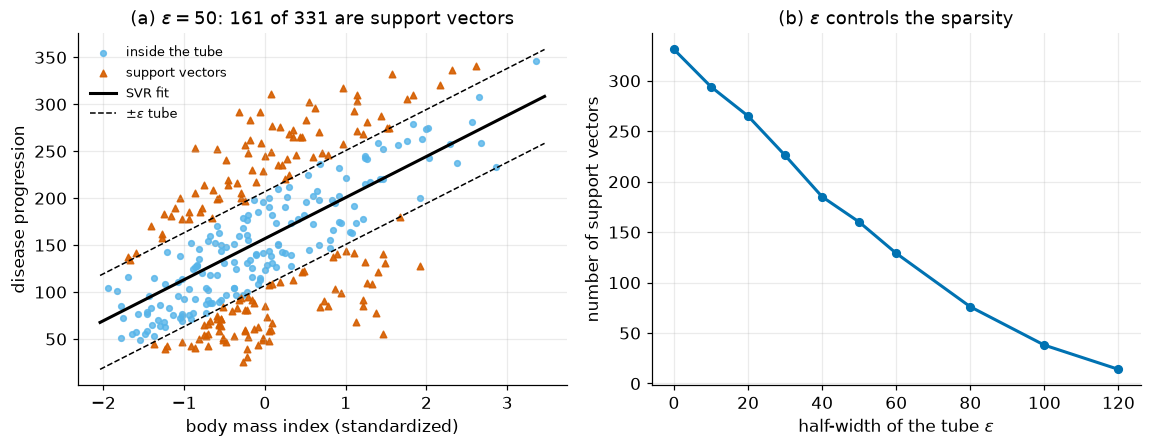

In [29]:
# Figure 8.8 — support vector regression on one feature of Diabetes: the epsilon-tube
def figure_8_8():
    fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.2))
    j = list(diab_s.feature_names).index("bmi")
    xb_tr = StandardScaler().fit_transform(Xd_tr[:, [j]])
    ax = axes[0]
    eps = 50
    m_ = SVR(kernel="linear", C=10, epsilon=eps, tol=1e-4).fit(xb_tr, yd_tr)
    grid_x = np.linspace(xb_tr.min() - 0.1, xb_tr.max() + 0.1, 100)[:, None]
    fit_ = m_.predict(grid_x)
    inside = np.abs(yd_tr - m_.predict(xb_tr)) < eps - 1e-6
    ax.scatter(xb_tr[inside], yd_tr[inside], s=14, color=SKY, alpha=0.8, label="inside the tube")
    ax.scatter(xb_tr[~inside], yd_tr[~inside], s=18, color=VERMILION, marker="^", alpha=0.9, label="support vectors")
    ax.plot(grid_x, fit_, color="k", lw=2, label="SVR fit")
    ax.plot(grid_x, fit_ + eps, color="k", lw=1.0, ls="--", label=r"$\pm\varepsilon$ tube")
    ax.plot(grid_x, fit_ - eps, color="k", lw=1.0, ls="--")
    ax.set(xlabel="body mass index (standardized)", ylabel="disease progression", title=f"(a) $\\varepsilon = {eps}$: {int((~inside).sum())} of {len(yd_tr)} are support vectors")
    ax.legend(frameon=False, fontsize=8.5, loc="upper left")
    ax = axes[1]
    eps_values = [0, 10, 20, 30, 40, 50, 60, 80, 100, 120]
    n_sv = [len(SVR(kernel="linear", C=10, epsilon=e, tol=1e-4).fit(xb_tr, yd_tr).support_) for e in eps_values]
    ax.plot(eps_values, n_sv, color=BLUE, lw=2, marker="o", ms=5)
    ax.set(xlabel=r"half-width of the tube $\varepsilon$", ylabel="number of support vectors", title="(b) $\\varepsilon$ controls the sparsity")
    fig.tight_layout()
    plt.show()


figure_8_8()

The test RMSE of least squares ($53.37$), ridge ($53.32$) and SVR ($53.0$ to $54.6$ according to $\varepsilon$) differ by less than two points, and the cross-validation RMSE of all of them is between $56.0$ and $56.6$: on $111$ test patients these differences are not resolved (the standard deviation of the target is $77.7$ and the RMSE of the baseline $74.9$). The $\varepsilon$-insensitive loss does not improve on the squared loss here, which is the likelihood-based choice when the noise is roughly Gaussian; its advantage would show with heavy-tailed noise, which we have not tested. What $\varepsilon$ buys is **sparsity**: all $331$ patients are support vectors for $\varepsilon = 0$ (where the loss is the absolute error $\lvert r\rvert$), $138$ for $\varepsilon = 50$ and only $25$ for $\varepsilon = 100$ (more than a standard deviation of the target), at a cost of $0.8$ points of RMSE with respect to least squares. Figure 8.8(a) shows the tube for the body mass index alone ($161$ of the $331$ patients are on or outside the tube of half-width $50$, with $C = 10$) and panel (b) the number of support vectors falling from $331$ to $15$ as $\varepsilon$ goes from $0$ to $120$.

## 8.9 Summary

- **Geometry.** The distance from $\mathbf{x}$ to the hyperplane $\mathbf{w}^\top\mathbf{x} + b = 0$ is $\lvert\mathbf{w}^\top\mathbf{x} + b\rvert/\lVert\mathbf{w}\rVert$ (Proposition 8.1). Among the hyperplanes that separate the data, the hard-margin SVM chooses the one with the largest margin by minimizing $\tfrac12\lVert\mathbf{w}\rVert^2$ subject to $y_i(\mathbf{w}^\top\mathbf{x}_i + b)\ge 1$; the margin is $1/\lVert\mathbf{w}\rVert$. In Worked example 8.1 the solution is $\mathbf{w} = (0, 1)$, $b = -1$, with three support vectors.
- **Duality (Theorems 8.2 and 8.4).** The dual maximizes $\sum_i\alpha_i - \tfrac12\sum_{i,j}\alpha_i\alpha_jy_iy_j\mathbf{x}_i^\top\mathbf{x}_j$ with $\sum_i\alpha_iy_i = 0$ and $\alpha_i\ge 0$ (and $\alpha_i\le C$ for the soft margin). Then $\mathbf{w} = \sum_i\alpha_iy_i\mathbf{x}_i$ and complementary slackness makes the solution *sparse*: only the **support vectors** ($\alpha_i > 0$) matter, and $\lVert\mathbf{w}\rVert^2 = \sum_i\alpha_i$ in the hard-margin case. On Iris (setosa/versicolor) two flowers out of $100$ determine the classifier, and on the Breast Cancer training set $36$ patients out of $426$ do ($C = 1$).
- **Soft margin and the hinge loss (Proposition 8.3).** With slacks, the SVM minimizes $\frac1n\sum_i\max\{0, 1 - m_i\} + \frac\lambda2\lVert\mathbf{w}\rVert^2$ with $\lambda = 1/(Cn)$: **a regularized linear classifier like the logistic regression of Chapter 6, with the hinge loss in place of the log-loss.** The examples are of three kinds: beyond the margin ($\alpha_i = 0$; $390$ of $426$ at $C = 1$), on it ($0 < \alpha_i < C$; $20$) and inside it or misclassified ($\alpha_i = C$; $16$). For a separable data set every $C\ge C_0$ (the largest hard-margin multiplier; $C_0 = 125$ on Breast Cancer) gives the hard-margin classifier exactly.
- **What the hinge loss estimates (Proposition 8.5).** Its population minimizer is $\operatorname{sign}(2\eta - 1)$, the Bayes classifier, and not $\eta$: the score is a distance, not a probability. Logistic regression has the same representation $\mathbf{w} = \sum_i\alpha_iy_i\mathbf{x}_i$ with $\alpha_i = C\sigma(-m_i)$, never exactly zero: the hinge loss hardens the sigmoid into a step. Probabilities for an SVM come from Platt scaling, which helps or not depending on $C$ (log-loss $0.167\to 0.103$ at $C = 0.03$, $0.120\to 0.130$ at $C = 1$).
- **Algorithms (Section 8.5).** The subgradient method with the step $1/(\lambda k)$ has the guarantee $G^2(1 + \ln K)/(2\lambda K)$ for the average iterate (Theorem 8.6; loose by three to four orders of magnitude on Breast Cancer, whose measured gaps decay like $1/k$), SMO updates two multipliers at a time with a closed-form step (Proposition 8.7; $20{,}899$ iterations at $C = 1$, against $9{,}524$ for libsvm's second-order choice of the pair), and dual coordinate descent solves the problem with the intercept in the weights. `SVC` (libsvm), `LinearSVC` (liblinear) and `SGDClassifier` solve slightly different problems because of the treatment of the intercept.
- **Generalization (Section 8.6).** The margin bound of Theorem 3.7 is vacuous on Breast Cancer with the worst-case radius ($1.7$ or more) and below $1$ with the root-mean-square radius only for $C\le 0.1$, but it correctly ranks the hard margin last: its capacity term, proportional to $\lVert\mathbf{w}\rVert$, is the largest ($28.4$) and its test error the highest ($7.0\%$). The leave-one-out error is bounded by the fraction of support vectors (Proposition 8.8), verified for eleven values of $C$ (bound loose when $C$ is small, tight when it is large). Cross-validation cannot tell apart the values of $C$ between $0.01$ and $100$: a coarse logarithmic grid is enough.
- **Practice (Section 8.7).** Standardize inside a pipeline: without it the libsvm solver needed $1.6\cdot 10^8$ iterations instead of $3\cdot 10^3$. On Breast Cancer the tuned SVM and the tuned logistic regression are statistically indistinguishable ($3$ against $5$ test errors, McNemar $p = 0.50$). On Digits one-vs-one ($9$ errors out of $450$) beats one-vs-rest ($20$; McNemar $p = 0.019$) and is suggestively better than the softmax regression ($16$; $p = 0.092$).
- **Beyond linear.** The dual uses only inner products, so $\mathbf{x}_i^\top\mathbf{x}_j$ can be replaced by a kernel $k(\mathbf{x}_i, \mathbf{x}_j)$: for $k = (\mathbf{x}^\top\mathbf{z} + 1)^2$ the kernel SVM and the linear SVM on the six explicit features have the same decision function (difference $\sim 10^{-10}$). On two Breast Cancer features the gain of a higher degree is small. **Support vector regression** minimizes the $\varepsilon$-insensitive loss; on Diabetes it does not beat least squares (test RMSE $53.0$ to $54.6$ against $53.4$), but $\varepsilon$ makes the solution sparse ($25$ support vectors out of $331$ for $\varepsilon = 100$).

### Data sources

- *Iris*: R. A. Fisher, "The use of multiple measurements in taxonomic problems", *Annals of Eugenics* 7(2), 179–188 (1936). Bundled with scikit-learn; Figures 8.1 and 8.2 use the petal length and width.
- *Breast Cancer Wisconsin (Diagnostic)*: W. N. Street, W. H. Wolberg and O. L. Mangasarian, "Nuclear feature extraction for breast tumor diagnosis", *IS&T/SPIE 1993 International Symposium on Electronic Imaging: Science and Technology*, volume 1905, 861–870 (1993). Bundled with scikit-learn. The target is recoded so that malignant $= +1$; the training and test sets are the stratified split of Chapters 6 and 7.
- *Digits*: E. Alpaydin and C. Kaynak, "Optical Recognition of Handwritten Digits", UCI Machine Learning Repository (1998). The test portion of the data set, 1,797 images of $8\times 8$ pixels, is bundled with scikit-learn.
- *Diabetes*: B. Efron, T. Hastie, I. Johnstone and R. Tibshirani, "Least Angle Regression", *Annals of Statistics* 32(2), 407–499 (2004). Bundled with scikit-learn.
- *Constructed data* (flagged in the text): the five points of Worked example 8.1 and the small data sets of Exercises 8.1, 8.2 and 8.5, chosen so that the solution can be found by hand. All the experiments of the chapter use the real data sets above.

### Further reading

- C. Cortes and V. Vapnik, "Support-vector networks", *Machine Learning* 20(3), 273–297 (1995), and B. E. Boser, I. M. Guyon and V. N. Vapnik, "A training algorithm for optimal margin classifiers", *COLT* 1992. The soft margin and the first kernel SVM.
- V. N. Vapnik, *Statistical Learning Theory*, Wiley, 1998. The theory behind the margin and the leave-one-out bound; see also V. Vapnik and O. Chapelle, "Bounds on error expectation for support vector machines", *Neural Computation* 12(9), 2013–2036 (2000).
- C. J. C. Burges, "A tutorial on support vector machines for pattern recognition", *Data Mining and Knowledge Discovery* 2(2), 121–167 (1998). A short and clear introduction with the geometry of Section 8.2.
- B. Schölkopf and A. J. Smola, *Learning with Kernels*, MIT Press, 2002, and T. Hastie, R. Tibshirani and J. Friedman, *The Elements of Statistical Learning*, 2nd ed., Springer, 2009, Chapter 12. The reference books; the second connects SVMs with regularization and with the loss functions of Section 8.4.
- S. Boyd and L. Vandenberghe, *Convex Optimization*, Cambridge University Press, 2004, Chapter 5. Lagrange duality and the KKT conditions used in Theorems 8.2 and 8.4.
- T. Zhang, "Statistical behavior and consistency of classification methods based on convex risk minimization", *Annals of Statistics* 32(1), 56–85 (2004), and P. L. Bartlett, M. I. Jordan and J. D. McAuliffe, "Convexity, classification, and risk bounds", *Journal of the American Statistical Association* 101(473), 138–156 (2006). Why minimizing the hinge loss leads to the Bayes classifier (Proposition 8.5).
- S. Rosset, J. Zhu and T. Hastie, "Margin maximizing loss functions", *Advances in Neural Information Processing Systems* 16, 2004. The regularization path of the logistic regression converges to the maximum-margin direction.
- E. Hazan, A. Agarwal and S. Kale, "Logarithmic regret algorithms for online convex optimization", *Machine Learning* 69, 169–192 (2007), the proof technique of Theorem 8.6, and S. Shalev-Shwartz, Y. Singer, N. Srebro and A. Cotter, "Pegasos: primal estimated sub-gradient solver for SVM", *Mathematical Programming* 127(1), 3–30 (2011).
- J. Platt, "Sequential minimal optimization: a fast algorithm for training support vector machines", Microsoft Research Technical Report MSR-TR-98-14 (1998); R.-E. Fan, P.-H. Chen and C.-J. Lin, "Working set selection using second order information for training support vector machines", *Journal of Machine Learning Research* 6, 1889–1918 (2005); C.-C. Chang and C.-J. Lin, "LIBSVM: a library for support vector machines", *ACM Transactions on Intelligent Systems and Technology* 2(3), 27 (2011). The SMO algorithm and its implementation.
- C.-J. Hsieh, K.-W. Chang, C.-J. Lin, S. S. Keerthi and S. Sundararajan, "A dual coordinate descent method for large-scale linear SVM", *ICML* 2008, and R.-E. Fan, K.-W. Chang, C.-J. Hsieh, X.-R. Wang and C.-J. Lin, "LIBLINEAR: a library for large linear classification", *Journal of Machine Learning Research* 9, 1871–1874 (2008).
- J. Platt, "Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods", in *Advances in Large Margin Classifiers*, MIT Press, 1999, and H.-T. Lin, C.-J. Lin and R. C. Weng, "A note on Platt's probabilistic outputs for support vector machines", *Machine Learning* 68, 267–276 (2007).
- C.-W. Hsu and C.-J. Lin, "A comparison of methods for multiclass support vector machines", *IEEE Transactions on Neural Networks* 13(2), 415–425 (2002), and K. Crammer and Y. Singer, "On the algorithmic implementation of multiclass kernel-based vector machines", *Journal of Machine Learning Research* 2, 265–292 (2001).
- H. Drucker, C. J. C. Burges, L. Kaufman, A. Smola and V. Vapnik, "Support vector regression machines", *Advances in Neural Information Processing Systems* 9, 1997, and A. J. Smola and B. Schölkopf, "A tutorial on support vector regression", *Statistics and Computing* 14(3), 199–222 (2004).

## 8.10 Exercises

Difficulty: ★ warm-up, ★★ core, ★★★ challenge. Try each exercise before reading the hint; solutions and detailed outlines are in [Appendix C](../appendices/appendix_c_solutions.ipynb).

### Manual (analytical) exercises

**Exercise 8.1 ★ — A hard-margin SVM by hand.** The negative points are $\mathbf{x}_1 = (0, 0)$, $\mathbf{x}_2 = (1, 1)$ and the positive points are $\mathbf{x}_3 = (2, 0)$, $\mathbf{x}_4 = (3, 1)$, $\mathbf{x}_5 = (4, -1)$. (a) Find the maximum-margin hyperplane $(\mathbf{w}, b)$ and the margin. (b) Find the multipliers $\boldsymbol\alpha$ and check that $\mathbf{w} = \sum_i\alpha_iy_i\mathbf{x}_i$, $\sum_i\alpha_iy_i = 0$ and $\lVert\mathbf{w}\rVert^2 = \sum_i\alpha_i$. (c) Which points lie on the margin hyperplanes, and which are support vectors? Are the two sets the same?

*Hint.* The closest pair of points of the two classes determines the direction of $\mathbf{w}$. For (c), look at the scores of all five points.

**Exercise 8.2 ★★ — Small $C$: the nearest-centroid classifier.** Let the training set be *balanced* ($n/2$ examples in each class) and $R = \max_i\lVert\mathbf{x}_i\rVert$. (a) Show that if $C\le 1/(2nR^2)$ then $\alpha_i = C$ for every $i$ is a solution of the dual and $\mathbf{w} = C\sum_iy_i\mathbf{x}_i = \frac{Cn}{2}(\bar{\mathbf{x}}_+ - \bar{\mathbf{x}}_-)$, where $\bar{\mathbf{x}}_\pm$ are the class means. (b) Apply it to the points $(0, 0), (1, 0)$ (negative) and $(0, 1), (1, 2)$ (positive). (c) Is the intercept $b$ determined by the KKT conditions?

*Hint.* Check the KKT conditions of Theorem 8.4: with all $\alpha_i = C$ you need $y_i(\mathbf{w}^\top\mathbf{x}_i + b)\le 1$ for every $i$, and $\sum_i\alpha_iy_i = C\sum_iy_i = 0$. Bound $\lvert\mathbf{w}^\top\mathbf{x}_i\rvert\le CnR^2$ and take $b = 0$.

**Exercise 8.3 ★★ — What the losses estimate.** Let $\eta = \mathbb{P}(y = 1\mid\mathbf{x})$ and consider the conditional risk $g(f) = \eta\,\ell(f) + (1 - \eta)\,\ell(-f)$ of the value $f$ of the score. (a) For the squared hinge loss $\ell(m) = \max\{0, 1 - m\}^2$, show that the minimizer is $f^\ast = 2\eta - 1$ and the minimum value is $4\eta(1 - \eta)$. (b) For the logistic loss $\ell(m) = \log(1 + e^{-m})$, show that $f^\ast = \ln\frac\eta{1 - \eta}$ and that the minimum value is the entropy of a Bernoulli($\eta$). (c) For $\eta = 0.8$ compute the three minimizers (with Proposition 8.5) and the minimum values; what does each say about $\eta$?

*Hint.* For (a) restrict first to $f\in[-1, 1]$, where both maxima are positive, and differentiate; then check that $g$ increases for $f > 1$ and decreases for $f < -1$. For (b) set $g'(f) = 0$ and use $\sigma(f) = \eta$.

**Exercise 8.4 ★★★ — From soft to hard.** The data are separable, $\hat{\boldsymbol\alpha}$ is a solution of the hard-margin dual, and $C_0 = \max_i\hat\alpha_i$. (a) Show that for every $C\ge C_0$, $\hat{\boldsymbol\alpha}$ is also a solution of the soft-margin dual, and deduce that the soft-margin $\mathbf{w}$ equals the hard-margin one. (b) For Worked example 8.1 find $C_0$, and compute the soft-margin solution for $C = 0.4$ by finding the multipliers and checking the KKT conditions of Theorem 8.4.

*Hint.* (a) The soft-margin dual maximizes the same function over a subset of the feasible set of the hard-margin dual. (b) In Worked example 8.1, $\hat{\boldsymbol\alpha} = (\tfrac14, \tfrac14, \tfrac12, 0, 0)$. For $C = 0.4$ the multiplier of $\mathbf{x}_3$ cannot exceed $C$: guess that $\alpha_3 = C$, that $\mathbf{x}_1, \mathbf{x}_2$ remain free support vectors, and that $\mathbf{x}_4, \mathbf{x}_5$ remain beyond the margin; use $\mathbf{w} = \sum_i\alpha_iy_i\mathbf{x}_i$, $\sum_i\alpha_iy_i = 0$ and the equality of the scores of the free support vectors.

**Exercise 8.5 ★★ — A kernel by hand.** In one dimension the points $x = -1, 0, 1$ have label $-1$ and the points $x = -3, 3$ have label $+1$. (a) Show that no classifier $\operatorname{sign}(wx + b)$ separates them. (b) With the feature map $\boldsymbol\phi(x) = (x, x^2)$ find the maximum-margin classifier in the plane, its margin and its support vectors, and a valid set of multipliers $\alpha_i$. (c) The kernel is $k(x, z) = xz + x^2z^2$. Write the classifier in terms of $k$ and the multipliers, and compute its value at $x = 0, 2, \sqrt5, 3$. (d) Is the set of multipliers unique?

*Hint.* In the plane the classes are separated by a horizontal line (a threshold on $x^2$). By the symmetry of the problem you can take the same multiplier at $x = \pm 1$ and the same at $x = \pm 3$.

### Python (computational) exercises

**Exercise 8.6 ★ — The path in $C$ on Iris.** Take the two overlapping species, versicolor and virginica, with the four features standardized inside a pipeline. For $C\in\{0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100\}$ report the number of support vectors, the training error, the 10-fold cross-validation error and the leave-one-out error, and check Proposition 8.8 numerically for each value of $C$. Which $C$ would you choose, and does the one-standard-error rule change the choice?

*Hint.* Use `cross_val_predict` with `LeaveOneOut()` and with `StratifiedKFold(10, shuffle=True, random_state=SEED)`; the number of support vectors is `len(model[-1].support_)` for a pipeline.

**Exercise 8.7 ★★ — Second-order working-set selection.** Modify the function `smo` of Section 8.5.2: keep the choice of $i$ (the example of $I_{\text{up}}$ with the largest $e_i$) and choose $j$ among the examples $t\in I_{\text{low}}$ with $e_t < e_i$ as the one that maximizes the decrease of the dual objective for the move of Proposition 8.7, $-\,(e_i - e_t)^2/(K_{ii} + K_{tt} - 2K_{it})$ (to be minimized). Compare the number of iterations of the two versions on the Breast Cancer problem for $C\in\{0.1, 1, 10\}$ with that of `SVC` (`n_iter_`), and check that both give the same $\mathbf{w}$ to within $10^{-5}$.

*Hint.* For a given $i$ the decrease of $D$ along the direction of Proposition 8.7 when $t$ is not clipped is $\text{gap}^2/(2a)$ with $\text{gap} = e_i - e_t$ and $a = K_{ii} + K_{tt} - 2K_{it}$. Vectorize over $t$.

**Exercise 8.8 ★★ — Pegasos with mini-batches.** Implement the mini-batch version of the subgradient method of Section 8.5.1 (average of the subgradients of $B$ examples drawn without replacement at each step, step $1/(\lambda k)$, projection on the ball) and run it on the Breast Cancer problem of that section for $B\in\{1, 8, 64, 426\}$ and $2\cdot 10^5$ examples in total. Plot the suboptimality of the last iterate against the number of epochs, and fit the slope on logarithmic axes. Does the batch size matter, at an equal number of epochs, as it did in Section 7.7.1?

*Hint.* Reuse `dual_coordinate_descent` for $f^\ast$ and `f_hinge` for the objective; the number of steps for a batch $B$ is $2\cdot 10^5/B$. Record the gap at logarithmically spaced epochs.

**Exercise 8.9 ★★★ — Support vectors and the sample size.** On the Breast Cancer data, for $n\in\{50, 100, 200, 426\}$ draw $30$ random stratified subsets of the training set, fit a linear SVM with $C = 0.1$ (on standardized features, fitted inside a pipeline on the subset), and record the fraction of support vectors, the leave-one-out error on the subset (by explicit refits) and the error on the common test set. Plot the three quantities against $n$ on logarithmic axes, with the means and the standard deviations over the $30$ draws. Does the fraction of support vectors decrease with $n$, and how does the test error compare with the leave-one-out error and with the bound of Proposition 8.8?

*Hint.* Use `train_test_split(..., train_size=n, stratify=..., random_state=seed)` for the subsets and the pipeline `make_pipeline(StandardScaler(), SVC(kernel="linear", C=0.1))`. The leave-one-out loop takes a few minutes in total; reduce the number of draws to $10$ while you debug.

**Exercise 8.10 ★★★ — Is support vector regression better than ridge?** On the Diabetes data, compare SVR with a linear kernel ($\varepsilon = 50$, $C$ chosen by $5$-fold cross-validation inside each split) with ridge regression ($\lambda$ chosen the same way) on $J = 20$ random splits of the 442 patients into $331$ training and $111$ test patients. Report the mean and standard deviation of the test RMSE of the two methods and the paired differences, and test the difference with the corrected resampled $t$-test of Section 5.5.2. Do the data allow to conclude?

*Hint.* The statistic is $t = \bar d/\sqrt{(1/J + n_{\text{test}}/n_{\text{train}})\,s_d^2}$ with $J - 1$ degrees of freedom (Exercise 6.6). Use `scipy.stats.t.sf` for the $p$-value. Fix the grids of $C$ and $\lambda$ in advance and use `GridSearchCV` inside a pipeline with standardization.

## What comes next

We have a convex, sparse, margin-based classifier, and its dual form is made of inner products. **Chapter 9** exploits this fact to the end: replacing $\mathbf{x}_i^\top\mathbf{x}_j$ by a kernel $k(\mathbf{x}_i, \mathbf{x}_j)$ gives nonlinear classifiers of infinite capacity that are still convex programs, and the **representer theorem** will show that the same reasoning applies to ridge regression (Proposition 6.12), to the logistic regression and to every penalized method of the form $\sum_i\ell(y_i, f(\mathbf{x}_i)) + \lambda\lVert f\rVert^2$. The `smo` function of this chapter, which uses only a Gram matrix, will work with kernels without any change, and the polynomial kernel of Section 8.8.1 will be joined by the Gaussian kernel. **Chapter 10** replaces the $\ell_2$ penalty by an $\ell_1$ penalty, which is also non-differentiable and also produces sparsity, but in the *features* (the coordinates of $\mathbf{w}$) and not in the examples; its algorithms, proximal gradient and coordinate descent, are close relatives of the subgradient method and of the dual coordinate descent of Section 8.5. **Chapter 11** returns to nonlinear models with decision trees and ensembles, whose probabilities need the recalibration of Section 8.7.3. In Part IV the **hinge loss** reappears as one of the losses for training neural networks, and the questions of this chapter (what a loss estimates, how a margin controls generalization, why the optimization finds a sparse or a large-margin solution) become central.